<a href="https://colab.research.google.com/github/IsmaeelDhikr/IsmaeelDhikr/blob/main/EdgeIIoTBenchmark.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [99]:
from google.colab import drive
drive.mount('/content/drive')

# Save dataframes to CSV
Xtrain_rf_shap.to_csv("/content/drive/MyDrive/eiotXtrain_rf_shap.csv", index=False)
Xtest_rf_shap.to_csv("/content/drive/MyDrive/eiotXtest_rf_shap.csv", index=False)
Xtrain_corr.to_csv("/content/drive/MyDrive/eiotXtrain_corr.csv", index=False)
Xtest_corr.to_csv("/content/drive/MyDrive/eiotXtest_corr.csv", index=False)

# Convert the list of consensus features to a pandas Series first to allow saving to CSV
pd.Series(consensus_features).to_csv("/content/drive/MyDrive/eiotconsensus_features.csv", index=False, header=["consensus_features"])

# Save the consensus dataframes
X_train_consensus.to_csv("/content/drive/MyDrive/eiotX_train_consensus.csv", index=False)
X_test_consensus.to_csv("/content/drive/MyDrive/eiotX_test_consensus.csv", index=False)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:


# Save inside Drive
map_classXiot.to_csv("/content/drive/MyDrive/map_classXiot.csv", index=False)

In [1]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from functools import partial
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    auc
)

from sklearn.utils import _safe_indexing

In [3]:
from google.colab import files
uploaded = files.upload()

Saving ML-EdgeIIoT-dataset.csv to ML-EdgeIIoT-dataset.csv


In [4]:
edgeiot = pd.read_csv("ML-EdgeIIoT-dataset.csv")
edgeiot.shape

/tmp/ipykernel_6662/1714227088.py:1: DtypeWarning: Columns (3,6,11,13,14,15,16,17,31,32,34,39,45,51,54,55) have mixed types. Specify dtype option on import or set low_memory=False.
  edgeiot = pd.read_csv("ML-EdgeIIoT-dataset.csv")


(157800, 63)

In [61]:
# Remove noisy columns:
## 1st row consists of addresses
## 2nd row consists of a single entry (0s)
## 3rd row consists os series of special characters

noisy_columns = ['frame.time','ip.src_host','ip.dst_host','arp.dst.proto_ipv4','arp.src.proto_ipv4','http.request.full_uri','http.request.method','mqtt.protoname','mqtt.topic',
                                     'icmp.unused','http.tls_port','dns.qry.type','dns.retransmit_request_in','mqtt.conack.flags','mqtt.msg_decoded_as','mbtcp.len','mbtcp.trans_id','mbtcp.unit_id',
                                     'http.file_data','http.request.uri.query','http.referer','http.request.version','tcp.options','tcp.payload','tcp.srcport','dns.qry.name.len','mqtt.msg'
                                     ]

In [62]:
noiseless = edgeiot.drop(columns=noisy_columns)
noiseless.shape

(157800, 36)

In [63]:
noiseless.head()

,arp.opcode,arp.hw.size,icmp.checksum,icmp.seq_le,icmp.transmit_timestamp,http.content_length,http.response,tcp.ack,tcp.ack_raw,tcp.checksum,...,mqtt.conflag.cleansess,mqtt.conflags,mqtt.hdrflags,mqtt.len,mqtt.msgtype,mqtt.proto_len,mqtt.topic_len,mqtt.ver,Attack_label,Attack_type
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,MITM
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,MITM
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,MITM
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,MITM
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,MITM


In [64]:
# Remove multiclass column
bin_eiot = noiseless.drop(columns='Attack_type')

# Check for duplicates
bin_eiot.duplicated().any
bin_eiot.duplicated().sum()

np.int64(5768)

In [65]:
# remove the duplicates (5765 instances)
bin_eiot.drop_duplicates(inplace=True)
bin_eiot.duplicated().sum()
print("Non duplicated clean data: ", bin_eiot.shape)

Non duplicated clean data:  (152032, 35)


In [66]:
from google.colab import drive
drive.mount('/content/drive')

# Save inside Drive
bin_eiot.to_csv("/content/drive/MyDrive/bin_eiot.csv", index=False)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
from google.colab import drive
drive.mount('/content/drive')

# load from google drive
import pandas as pd
bin_eiot = pd.read_csv("/content/drive/MyDrive/bin_eiot.csv")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
# Separate the binary class data into features and binary class
features= bin_eiot.drop(columns="Attack_label")
target = bin_eiot.Attack_label

bin_eiot.shape, features.shape, target.shape

((152032, 35), (152032, 34), (152032,))

In [6]:
# Split the dataset
Xtrain, Xtest, ytrain, ytest = train_test_split(features, target, test_size=0.3, stratify=target, random_state=42)


In [7]:
# Define Classifiers
classifiers = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        #class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        #n_estimators=200,
        #class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "SVM": SVC(
        kernel="rbf",
        #C=1.0,
        #probability=True,
        #class_weight="balanced",
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        #n_neighbors=5,
        #weights="distance",
        n_jobs=-1
    ),

    "MLP": MLPClassifier(
        max_iter=1000,
        random_state=42
    ),
    "Naive Bayes": GaussianNB()
}

In [8]:
# Configure leakage-safe pipelines
from sklearn.preprocessing import StandardScaler

n_features = Xtrain.shape[1]

def build_pipeline(classifier):
    return Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", clone(classifier))
    ])

In [18]:
# Five-fold cross-validation and evaluation
# Cross-validation configuration
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

folds = list(cv.split(Xtrain, ytrain))

y_train_array = np.asarray(ytrain)

# Define the target classes globally
classes = np.unique(y_train_array)

# Store all experimental results
cv_results = []

# Store out-of-fold predictions and probabilities
oof_predictions = {}
oof_probabilities = {}

# Store fitted pipelines
fitted_models = {}

# Positive class for binary ROC-AUC (1 represents "Attack")
positive_label = 1 if 1 in classes else classes[-1]

for name, classifier in classifiers.items():

    print("\n" + "=" * 70)
    print(f"CLASSIFIER: {name}")
    print("=" * 70)

    pipeline = build_pipeline(classifier)

    # Out-of-fold storage
    oof_pred = np.empty(
        len(y_train_array),
        dtype=object
    )

    oof_prob = np.zeros(
        (len(y_train_array), len(classes))
    )

    fold_metrics = []

    # Five-fold evaluation
    for fold_number, (train_idx, val_idx) in enumerate(folds, start=1):

        X_fold_train = _safe_indexing(Xtrain, train_idx)
        X_fold_val = _safe_indexing(Xtrain, val_idx)

        y_fold_train = y_train_array[train_idx]
        y_fold_val = y_train_array[val_idx]

        model = clone(pipeline)
        model.fit(X_fold_train, y_fold_train)

        # Predictions
        predictions = model.predict(X_fold_val)

        # Probability estimates
        if hasattr(model.named_steps["classifier"], "predict_proba"):
            probabilities = model.predict_proba(X_fold_val)
        else:
            # fallback for models like linear SVM without probability=True
            decision_function = model.decision_function(X_fold_val)
            # Convert 1D decision function to pseudo-probabilities for binary classification
            exp_dec = np.exp(decision_function)
            probabilities = np.vstack([1 / (1 + exp_dec), exp_dec / (1 + exp_dec)]).T

        # Align probabilities with global class order
        fold_classes = model.named_steps["classifier"].classes_

        aligned_prob = np.zeros((len(val_idx), len(classes)))

        for j, label in enumerate(fold_classes):
            global_index = np.where(classes == label)[0][0]
            aligned_prob[:, global_index] = probabilities[:, j]

        oof_pred[val_idx] = predictions
        oof_prob[val_idx] = aligned_prob

        # Fold evaluation
        fold_accuracy = accuracy_score(y_fold_val, predictions)

        fold_precision = precision_score(
            y_fold_val,
            predictions,
            labels=classes,
            average="macro",
            zero_division=0
        )

        fold_recall = recall_score(
            y_fold_val,
            predictions,
            labels=classes,
            average="macro",
            zero_division=0
        )

        fold_f1 = f1_score(
            y_fold_val,
            predictions,
            labels=classes,
            average="macro",
            zero_division=0
        )

        if len(classes) == 2:
            pos_idx = np.where(classes == positive_label)[0][0]
            fold_auc = roc_auc_score((y_fold_val == positive_label).astype(int), aligned_prob[:, pos_idx])
        else:
            fold_auc = roc_auc_score(
                y_fold_val,
                aligned_prob,
                labels=classes,
                multi_class="ovr",
                average="macro"
            )

        fold_metrics.append({
            "Fold": fold_number,
            "Accuracy": fold_accuracy,
            "Precision": fold_precision,
            "Recall": fold_recall,
            "F1": fold_f1,
            "ROC_AUC": fold_auc
        })

        print(
            f"Fold {fold_number}: "
            f"Accuracy={fold_accuracy:.4f}, "
            f"F1={fold_f1:.4f}, "
            f"AUC={fold_auc:.4f}"
        )

    # Store OOF outputs
    oof_predictions[name] = oof_pred
    oof_probabilities[name] = oof_prob

    fold_df = pd.DataFrame(fold_metrics)

    # Mean and standard deviation across folds
    cv_results.append({
        "Classifier": name,
        "Accuracy Mean": fold_df["Accuracy"].mean(),
        "Accuracy SD": fold_df["Accuracy"].std(ddof=1),
        "Precision Mean": fold_df["Precision"].mean(),
        "Precision SD": fold_df["Precision"].std(ddof=1),
        "Recall Mean": fold_df["Recall"].mean(),
        "Recall SD": fold_df["Recall"].std(ddof=1),
        "F1 Mean": fold_df["F1"].mean(),
        "F1 SD": fold_df["F1"].std(ddof=1),
        "ROC-AUC Mean": fold_df["ROC_AUC"].mean(),
        "ROC-AUC SD": fold_df["ROC_AUC"].std(ddof=1)
    })

    # Fit final pipeline on all development data
    final_pipeline = clone(pipeline)
    final_pipeline.fit(Xtrain, ytrain)
    fitted_models[name] = final_pipeline

print("\nSix-classifier cross-validation completed.")


CLASSIFIER: Logistic Regression
Fold 1: Accuracy=0.9007, F1=0.7604, AUC=0.8909
Fold 2: Accuracy=0.8983, F1=0.7543, AUC=0.8874
Fold 3: Accuracy=0.9002, F1=0.7615, AUC=0.8886
Fold 4: Accuracy=0.9007, F1=0.7611, AUC=0.8917
Fold 5: Accuracy=0.8997, F1=0.7576, AUC=0.8893

CLASSIFIER: Random Forest
Fold 1: Accuracy=0.9953, F1=0.9911, AUC=0.9999
Fold 2: Accuracy=0.9960, F1=0.9925, AUC=0.9999
Fold 3: Accuracy=0.9957, F1=0.9919, AUC=0.9999
Fold 4: Accuracy=0.9956, F1=0.9918, AUC=0.9999
Fold 5: Accuracy=0.9961, F1=0.9927, AUC=0.9999

CLASSIFIER: SVM
Fold 1: Accuracy=0.9099, F1=0.7827, AUC=0.9315
Fold 2: Accuracy=0.9090, F1=0.7801, AUC=0.9283
Fold 3: Accuracy=0.9102, F1=0.7848, AUC=0.9328
Fold 4: Accuracy=0.9101, F1=0.7837, AUC=0.9298
Fold 5: Accuracy=0.9089, F1=0.7801, AUC=0.9324

CLASSIFIER: KNN
Fold 1: Accuracy=0.9583, F1=0.9196, AUC=0.9793
Fold 2: Accuracy=0.9577, F1=0.9179, AUC=0.9791
Fold 3: Accuracy=0.9589, F1=0.9210, AUC=0.9814
Fold 4: Accuracy=0.9585, F1=0.9206, AUC=0.9802
Fold 5: Accur

In [19]:
cv_summary = pd.DataFrame(cv_results)

print("\nCROSS-VALIDATION COMPARATIVE RESULTS")

display(cv_summary.round(4).sort_values("F1 Mean", ascending=False))


CROSS-VALIDATION COMPARATIVE RESULTS


,Classifier,Accuracy Mean,Accuracy SD,Precision Mean,Precision SD,Recall Mean,Recall SD,F1 Mean,F1 SD,ROC-AUC Mean,ROC-AUC SD
1,Random Forest,0.9957,0.0003,0.9919,0.0014,0.9922,0.0007,0.9920,0.0006,0.9999,0.0000
4,MLP,0.9693,0.0025,0.9567,0.0045,0.9261,0.0094,0.9405,0.0053,0.9951,0.0005
3,KNN,0.9585,0.0005,0.9325,0.0015,0.9088,0.0035,0.9201,0.0014,0.9800,0.0009
2,SVM,0.9096,0.0006,0.9272,0.0015,0.7256,0.0022,0.7823,0.0021,0.9310,0.0019
0,Logistic Regression,0.8999,0.0010,0.8925,0.0034,0.7076,0.0029,0.7590,0.0030,0.8896,0.0017
5,Naive Bayes,0.8928,0.0013,0.9392,0.0007,0.6635,0.0041,0.7162,0.0049,0.6618,0.0036


In [20]:
# Tabular presentation in mean ± standard deviation format
publication_table = pd.DataFrame()

publication_table["Classifier"] = cv_summary["Classifier"]

for metric in [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC"
]:

    publication_table[metric] = [
        f"{mean:.4f} ± {std:.4f}"
        for mean, std in zip(
            cv_summary[f"{metric} Mean"],
            cv_summary[f"{metric} SD"]
        )
    ]

display(publication_table.sort_values("F1", ascending=False))

,Classifier,Accuracy,Precision,Recall,F1,ROC-AUC
1,Random Forest,0.9957 ± 0.0003,0.9919 ± 0.0014,0.9922 ± 0.0007,0.9920 ± 0.0006,0.9999 ± 0.0000
4,MLP,0.9693 ± 0.0025,0.9567 ± 0.0045,0.9261 ± 0.0094,0.9405 ± 0.0053,0.9951 ± 0.0005
3,KNN,0.9585 ± 0.0005,0.9325 ± 0.0015,0.9088 ± 0.0035,0.9201 ± 0.0014,0.9800 ± 0.0009
2,SVM,0.9096 ± 0.0006,0.9272 ± 0.0015,0.7256 ± 0.0022,0.7823 ± 0.0021,0.9310 ± 0.0019
0,Logistic Regression,0.8999 ± 0.0010,0.8925 ± 0.0034,0.7076 ± 0.0029,0.7590 ± 0.0030,0.8896 ± 0.0017
5,Naive Bayes,0.8928 ± 0.0013,0.9392 ± 0.0007,0.6635 ± 0.0041,0.7162 ± 0.0049,0.6618 ± 0.0036


In [21]:
# Separate Classification for each classifier
class_names = ["Normal", "Attack"]

for name in classifiers:

    print("\n" + "=" * 75)
    print(f"CLASSIFICATION REPORT: {name}")
    print("=" * 75)

    print(
        classification_report(
            y_train_array,
            oof_predictions[name].astype(int), # Cast to int to align with classes
            labels=classes,
            target_names=class_names,
            digits=4,
            zero_division=0
        )
    )


CLASSIFICATION REPORT: Logistic Regression
              precision    recall  f1-score   support

      Normal     0.8836    0.4258    0.5747     16899
      Attack     0.9013    0.9894    0.9433     89523

    accuracy                         0.8999    106422
   macro avg     0.8924    0.7076    0.7590    106422
weighted avg     0.8985    0.8999    0.8848    106422


CLASSIFICATION REPORT: Random Forest
              precision    recall  f1-score   support

      Normal     0.9862    0.9870    0.9866     16899
      Attack     0.9975    0.9974    0.9975     89523

    accuracy                         0.9957    106422
   macro avg     0.9919    0.9922    0.9920    106422
weighted avg     0.9957    0.9957    0.9957    106422


CLASSIFICATION REPORT: SVM
              precision    recall  f1-score   support

      Normal     0.9478    0.4560    0.6158     16899
      Attack     0.9065    0.9953    0.9488     89523

    accuracy                         0.9096    106422
   macro avg     0

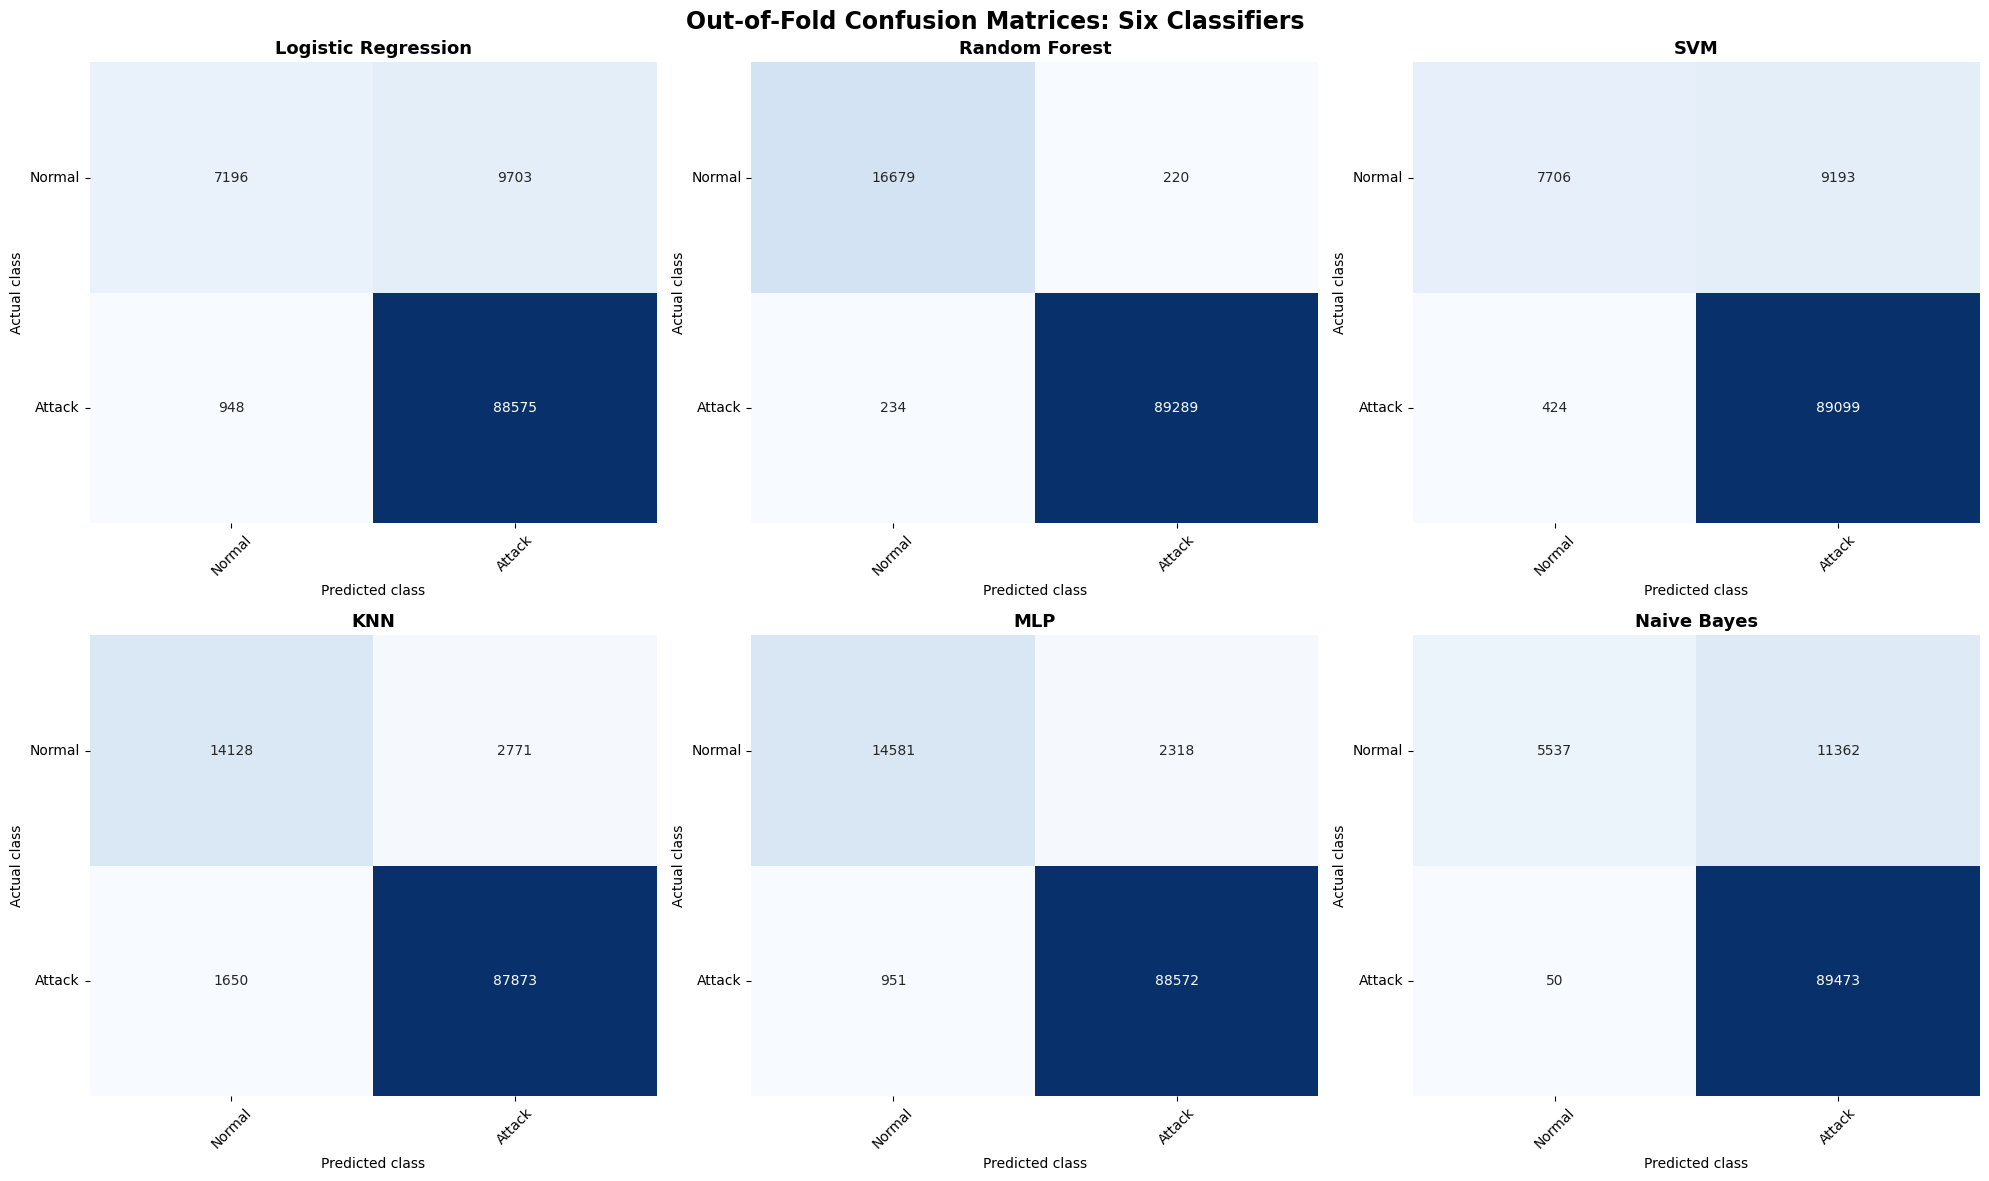

In [22]:
# Confusion matrices
fig, axes = plt.subplots(2, 3, figsize=(20, 12))

axes = axes.flatten()

for ax, name in zip(axes, classifiers):

    # Cast the out-of-fold predictions to int to match y_train_array
    cm = confusion_matrix(y_train_array, oof_predictions[name].astype(int), labels=classes)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax,
        cbar=False
    )

    ax.set_title(name, fontsize=13, fontweight="bold")

    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")

    ax.tick_params(axis="x", rotation=45)
    ax.tick_params(axis="y", rotation=0)

plt.suptitle("Out-of-Fold Confusion Matrices: Six Classifiers", fontsize=17, fontweight="bold")

plt.tight_layout()
plt.show()

In [23]:
# Export each confusion matrix

for name in classifiers:

    # Cast the out-of-fold predictions to int to match y_train_array
    cm = confusion_matrix(
        y_train_array,
        oof_predictions[name].astype(int),
        labels=classes
    )

    cm_df = pd.DataFrame(
        cm,
        index=class_names,
        columns=class_names
    )

    print(f"\n{name} - Confusion Matrix")

    display(cm_df)


Logistic Regression - Confusion Matrix


,Normal,Attack
Normal,7196,9703
Attack,948,88575



Random Forest - Confusion Matrix


,Normal,Attack
Normal,16679,220
Attack,234,89289



SVM - Confusion Matrix


,Normal,Attack
Normal,7706,9193
Attack,424,89099


... (2 outputs left out)


MLP - Confusion Matrix


,Normal,Attack
Normal,14581,2318
Attack,951,88572



Naive Bayes - Confusion Matrix


,Normal,Attack
Normal,5537,11362
Attack,50,89473


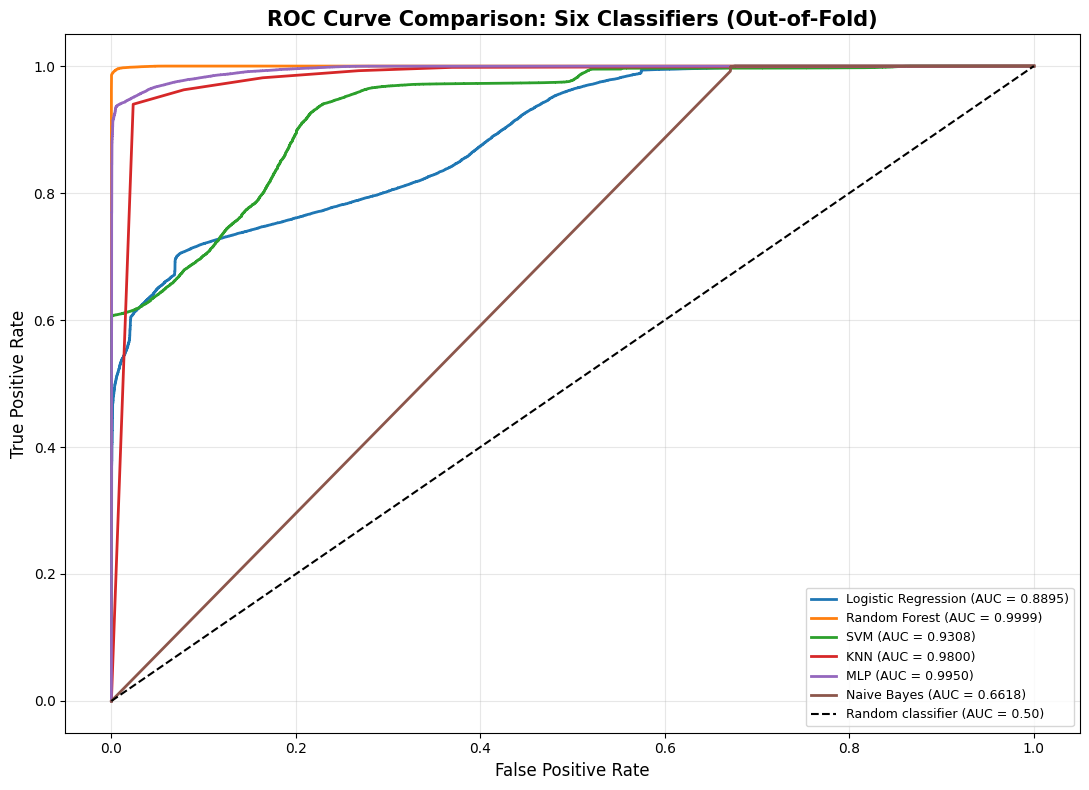

In [24]:
# Binary ROC Curve
# The actual classes are integers: 0 (Normal) and 1 (Attack)
positive_label = 1

plt.figure(figsize=(11, 8))

for name in classifiers:

    probabilities = oof_probabilities[name]
    positive_index = np.where(classes == positive_label)[0][0]
    scores = probabilities[:, positive_index]
    y_binary = (y_train_array == positive_label).astype(int)

    fpr, tpr, _ = roc_curve(y_binary, scores)
    auc_score = roc_auc_score(y_binary, scores)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc_score:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="black",
    linewidth=1.5,
    label="Random classifier (AUC = 0.50)"
)

plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate", fontsize=12)

plt.title(
    "ROC Curve Comparison: Six Classifiers (Out-of-Fold)",
    fontsize=15,
    fontweight="bold"
)

plt.legend(loc="lower right", fontsize=9)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [25]:
# NOW Independent test evaluation of all six classifiers
test_results = []

test_predictions = {}
test_probabilities = {}

for name, model in fitted_models.items():

    # Predict test observations
    predictions = model.predict(Xtest)

    # Dynamic probability estimates with fallback for models without predict_proba (like default SVC)
    if hasattr(model, "predict_proba"):
        probabilities = model.predict_proba(Xtest)
    elif hasattr(model, "decision_function"):
        decision_function = model.decision_function(Xtest)
        # Convert 1D decision function to pseudo-probabilities for binary classification
        exp_dec = np.exp(decision_function)
        probabilities = np.vstack([1 / (1 + exp_dec), exp_dec / (1 + exp_dec)]).T
    else:
        raise AttributeError(f"Model {name} has neither predict_proba nor decision_function.")

    test_predictions[name] = predictions
    test_probabilities[name] = probabilities

    # Metrics
    accuracy = accuracy_score(ytest, predictions)

    precision = precision_score(
        ytest,
        predictions,
        labels=classes,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        ytest,
        predictions,
        labels=classes,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        ytest,
        predictions,
        labels=classes,
        average="macro",
        zero_division=0
    )

    if len(classes) == 2:
        pos_idx = np.where(classes == positive_label)[0][0]
        auc_score = roc_auc_score((np.asarray(ytest) == positive_label).astype(int), probabilities[:, pos_idx])
    else:
        auc_score = roc_auc_score(
            ytest,
            probabilities,
            labels=classes,
            multi_class="ovr",
            average="macro"
        )

    test_results.append({
        "Classifier": name,
        "Accuracy": accuracy,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": f1,
        "Macro ROC-AUC": auc_score
    })

    # Named classification report
    print("\n" + "=" * 75)
    print(f"INDEPENDENT TEST CLASSIFICATION REPORT: {name}")
    print("=" * 75)

    print(
        classification_report(
            ytest,
            predictions,
            labels=classes,
            target_names=class_names,
            digits=4,
            zero_division=0
        )
    )


INDEPENDENT TEST CLASSIFICATION REPORT: Logistic Regression
              precision    recall  f1-score   support

      Normal     0.8771    0.4167    0.5650      7242
      Attack     0.8998    0.9890    0.9423     38368

    accuracy                         0.8981     45610
   macro avg     0.8885    0.7029    0.7537     45610
weighted avg     0.8962    0.8981    0.8824     45610


INDEPENDENT TEST CLASSIFICATION REPORT: Random Forest
              precision    recall  f1-score   support

      Normal     0.9832    0.9869    0.9850      7242
      Attack     0.9975    0.9968    0.9972     38368

    accuracy                         0.9952     45610
   macro avg     0.9904    0.9919    0.9911     45610
weighted avg     0.9953    0.9952    0.9952     45610


INDEPENDENT TEST CLASSIFICATION REPORT: SVM
              precision    recall  f1-score   support

      Normal     0.9446    0.4450    0.6050      7242
      Attack     0.9048    0.9951    0.9478     38368

    accuracy         

In [26]:
# Comparative Independent test results
test_summary = pd.DataFrame(test_results)

test_summary = test_summary.sort_values("Macro F1", ascending=False)

display(test_summary.round(4))

,Classifier,Accuracy,Macro Precision,Macro Recall,Macro F1,Macro ROC-AUC
1,Random Forest,0.9952,0.9904,0.9919,0.9911,0.9999
4,MLP,0.9674,0.9435,0.9334,0.9384,0.9949
3,KNN,0.9601,0.9349,0.9126,0.9233,0.9808
2,SVM,0.9077,0.9247,0.7201,0.7764,0.9273
0,Logistic Regression,0.8981,0.8885,0.7029,0.7537,0.8868
5,Naive Bayes,0.8917,0.9395,0.6598,0.7118,0.6588


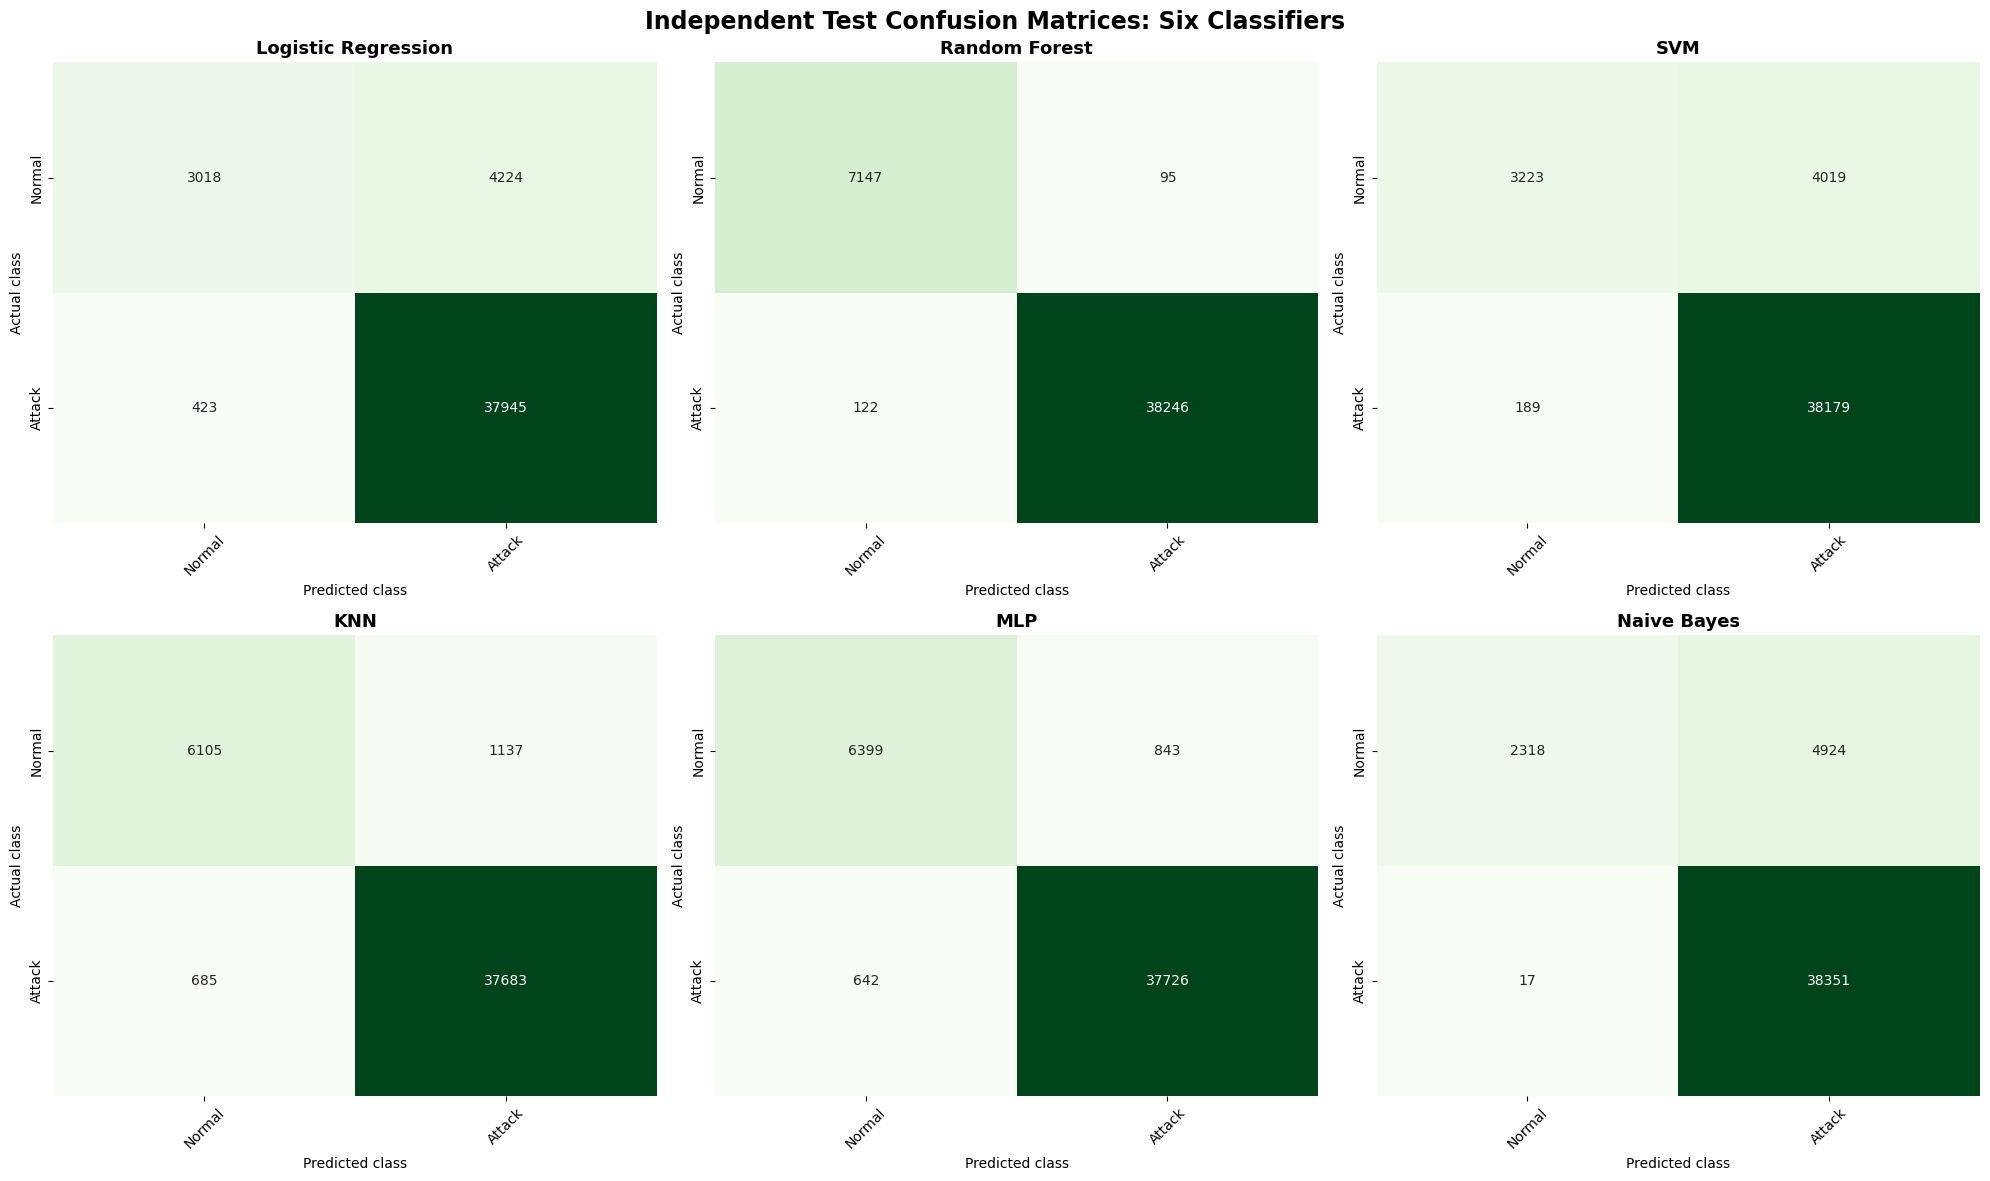

In [27]:
# Six independent test confusion matrices
fig, axes = plt.subplots(2, 3, figsize=(20, 12))

axes = axes.flatten()

for ax, name in zip(axes, classifiers):

    cm = confusion_matrix(
        ytest,
        test_predictions[name],
        labels=classes
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Greens",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax,
        cbar=False
    )

    ax.set_title(name, fontsize=13, fontweight="bold")
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")

    ax.tick_params(axis="x", rotation=45)

plt.suptitle(
    "Independent Test Confusion Matrices: Six Classifiers",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

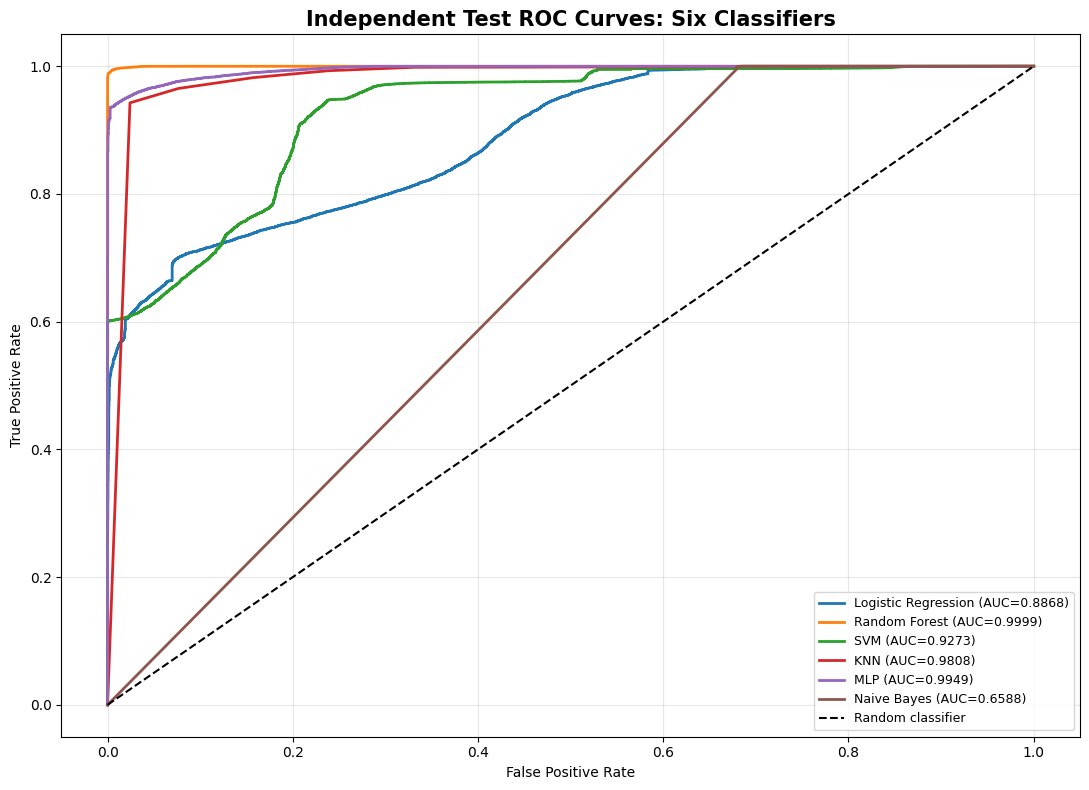

In [28]:
# Independent test ROC Curves ---- Binary Classification
if len(classes) == 2:

    plt.figure(figsize=(11, 8))

    y_test_binary = (np.asarray(ytest) == positive_label).astype(int)

    pos_idx = np.where(classes == positive_label)[0][0]

    for name in classifiers:

        scores = test_probabilities[name][:, pos_idx]

        fpr, tpr, _ = roc_curve(y_test_binary, scores)

        test_auc = roc_auc_score(y_test_binary, scores)

        plt.plot(
            fpr,
            tpr,
            linewidth=2,
            label=f"{name} (AUC={test_auc:.4f})"
        )

    plt.plot(
        [0, 1], [0, 1],
        linestyle="--",
        color="black",
        label="Random classifier"
    )

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")

    plt.title(
        "Independent Test ROC Curves: Six Classifiers",
        fontsize=15,
        fontweight="bold"
    )

    plt.legend(loc="lower right", fontsize=9)
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

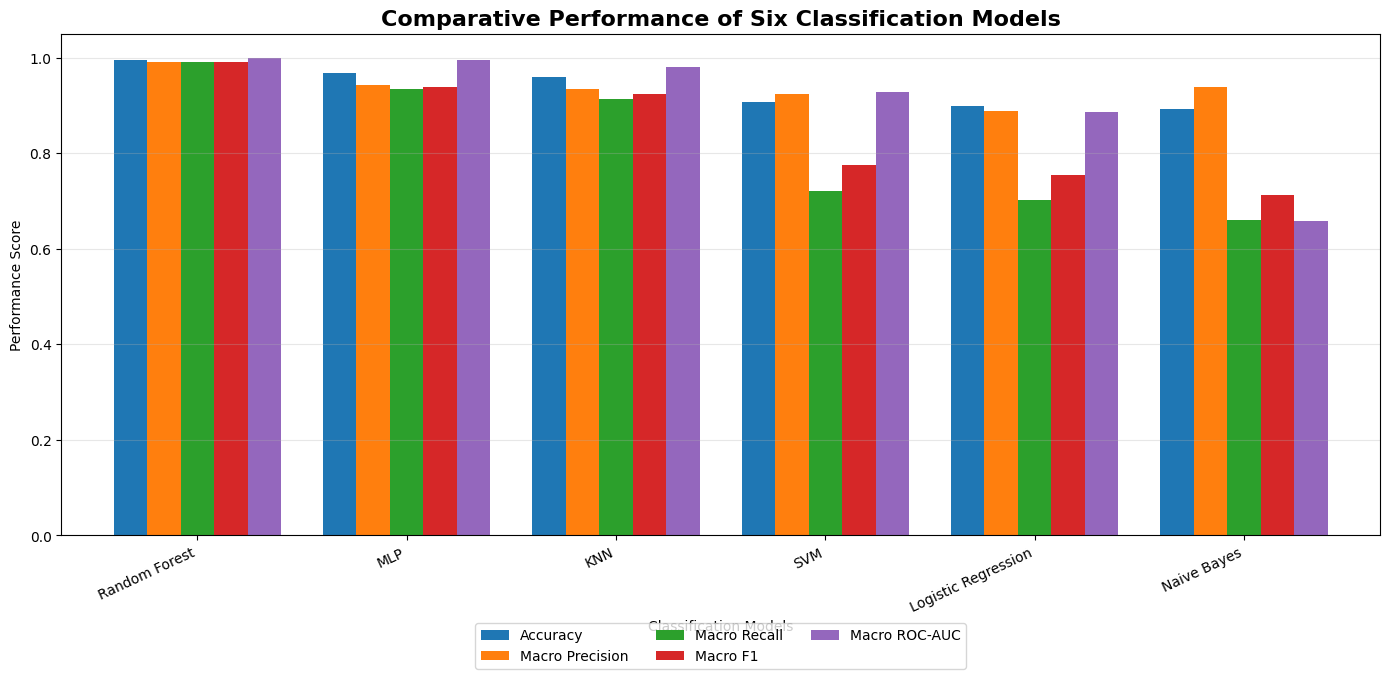

In [29]:
# Visual Comparison of the six classifiers
metrics_to_plot = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "Macro ROC-AUC"
]

plot_data = test_summary.set_index(
    "Classifier"
)[metrics_to_plot]

ax = plot_data.plot(
    kind="bar",
    figsize=(14, 7),
    width=0.8
)

ax.set_title(
    "Comparative Performance of Six Classification Models",
    fontsize=16,
    fontweight="bold"
)

ax.set_ylabel("Performance Score")
ax.set_xlabel("Classification Models")

ax.set_ylim(0, 1.05)
ax.legend(
    loc="lower center",
    bbox_to_anchor=(0.5, -0.28),
    ncol=3
)

plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [30]:
import joblib

# save inside drive
joblib.dump(fitted_models, "/content/drive/MyDrive/eiotfitted_models.pkl")
joblib.dump(final_pipeline, "/content/drive/MyDrive/eiotfinal_pipeline.pkl")

['/content/drive/MyDrive/eiotfinal_pipeline.pkl']

In [75]:
import shap

In [76]:
RANDOM_STATE = 42

BACKGROUND_SIZE = 100
EXPLANATION_SIZE = 200

# Sample background only from training observations
X_background = shap.sample(
    Xtrain,
    min(BACKGROUND_SIZE, len(Xtrain)),
    random_state=RANDOM_STATE
)

# Explain a representative sample of independent test observations
X_explain = shap.sample(
    Xtest,
    min(EXPLANATION_SIZE, len(Xtest)),
    random_state=RANDOM_STATE
)

# Preserve original feature names
if isinstance(Xtrain, pd.DataFrame):

    feature_names = list(Xtrain.columns)

    X_background = pd.DataFrame(
        X_background,
        columns=feature_names
    )

    X_explain = pd.DataFrame(
        X_explain,
        columns=feature_names
    )

else:

    feature_names = [
        f"Feature_{i}"
        for i in range(Xtrain.shape[1])
    ]

    X_background = pd.DataFrame(
        X_background,
        columns=feature_names
    )

    X_explain = pd.DataFrame(
        X_explain,
        columns=feature_names
    )

In [77]:
# Store SHAP results for all classifiers
shap_explanations = {}

# Map integer classes to string names
class_mapping = {0: "Normal", 1: "Attack"}

# Choose the class to explain (e.g., target_class = 1 for 'Attack')
target_class = 1

# Explicitly define classes in case the previous cell was not executed
import numpy as np
classes = np.unique(ytrain)

target_class_index = np.where(
    classes == target_class
)[0][0]

print("Explaining class:", class_mapping.get(
    target_class, str(target_class)
))

Explaining class: Attack


In [78]:
def extract_class_shap_values(
    shap_output,
    class_index,
    n_features
):

    if isinstance(shap_output, list):

        values = np.asarray(
            shap_output[class_index]
        )

    elif hasattr(shap_output, "values"):

        values = np.asarray(
            shap_output.values
        )

    else:

        values = np.asarray(shap_output)

    if values.ndim == 3:

        if values.shape[1] == n_features:
            # (samples, features, classes)
            values = values[:, :, class_index]

        elif values.shape[2] == n_features:
            # (classes, samples, features)
            values = values[class_index, :, :]

        else:
            raise ValueError(
                f"Unexpected SHAP shape: {values.shape}"
            )

    if values.ndim != 2:
        raise ValueError(
            f"Expected 2D SHAP values, got {values.shape}"
        )

    return values

In [82]:
tree_models = [
    "Random Forest"
]

linear_models = [
    "Logistic Regression"
]

kernel_models = [
    "SVM",
    "KNN",
    "MLP",
    "Naive Bayes"
]

for name, fitted_model in fitted_models.items():

    print("\nExplaining:", name)

    # Original pipeline components
    scaler = fitted_model.named_steps["scaler"]
    estimator = fitted_model.named_steps["classifier"]

    # Convert inputs to raw values to prevent scikit-learn feature-name validation warnings
    background_raw = X_background.values
    explain_raw = X_explain.values

    # Apply the already-fitted preprocessing transformations
    background_scaled = scaler.transform(background_raw)
    explain_scaled = scaler.transform(explain_raw)

    background_df = pd.DataFrame(
        background_scaled,
        columns=feature_names
    )

    explain_df = pd.DataFrame(
        explain_scaled,
        columns=feature_names
    )

    # Tree-based SHAP
    if name in tree_models:

        explainer = shap.TreeExplainer(
            estimator
        )

        shap_output = explainer(
            explain_df
        )

        shap_values = extract_class_shap_values(
            shap_output,
            target_class_index,
            len(feature_names)
        )

        expected_value = explainer.expected_value

        # Save explanation
        shap_explanations[name] = {
            "values": shap_values,
            "data": explain_df,
            "features": feature_names,
            "expected_value": expected_value
        }

    # Linear SHAP
    elif name in linear_models:

        explainer = shap.LinearExplainer(
            estimator,
            background_df
        )

        shap_output = explainer(
            explain_df
        )

        shap_values = extract_class_shap_values(
            shap_output,
            target_class_index,
            len(feature_names)
        )

        shap_explanations[name] = {
            "values": shap_values,
            "data": explain_df,
            "features": feature_names
        }

    # Kernel SHAP
    elif name in kernel_models:

        # Create a predictor function that works even if predict_proba is not available
        if hasattr(fitted_model, "predict_proba"):
            predict_fn = lambda x: fitted_model.predict_proba(x)
        else:
            def predict_fn(X):
                dec = fitted_model.decision_function(X)
                prob_pos = 1.0 / (1.0 + np.exp(-dec))
                return np.vstack([1.0 - prob_pos, prob_pos]).T

        background_small = shap.sample(
            X_background,
            min(20, len(X_background)),
            random_state=RANDOM_STATE
        )

        explainer = shap.KernelExplainer(
            predict_fn,
            background_small
        )

        # Reduce nsamples slightly for faster processing during SVM/KNN explanations
        shap_output = explainer.shap_values(
            X_explain,
            nsamples=50
        )

        shap_values = extract_class_shap_values(
            shap_output,
            target_class_index,
            X_explain.shape[1]
        )

        shap_explanations[name] = {
            "values": shap_values,
            "data": X_explain,
            "features": np.asarray(feature_names)
        }

    print(
        "SHAP computation completed:",
        shap_values.shape
    )


Explaining: Logistic Regression
SHAP computation completed: (200, 34)

Explaining: Random Forest


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


SHAP computation completed: (200, 34)

Explaining: SVM


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


  0%|          | 0/200 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

... (10 outputs left out)

  0%|          | 0/200 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

SHAP computation completed: (200, 34)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

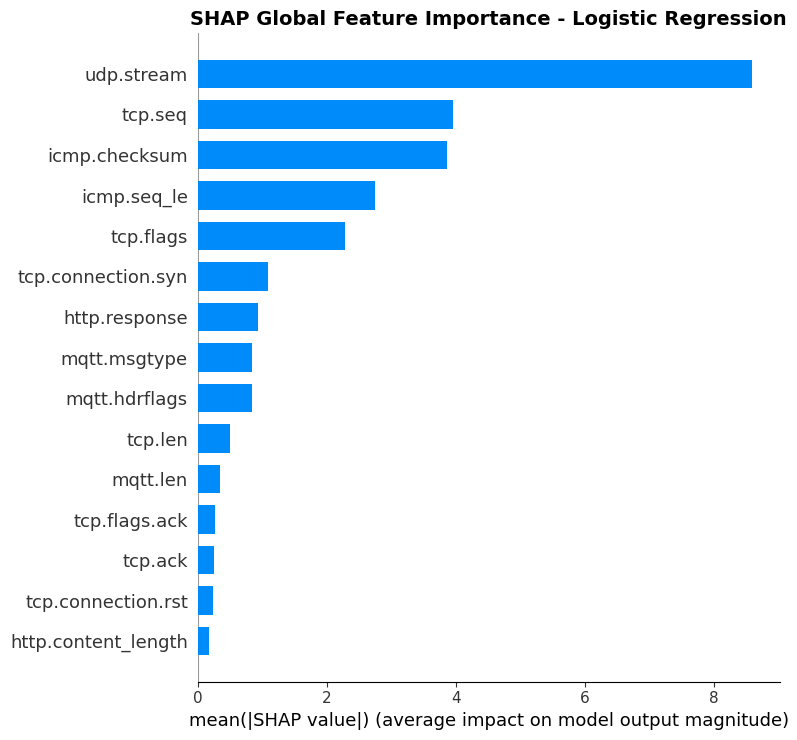

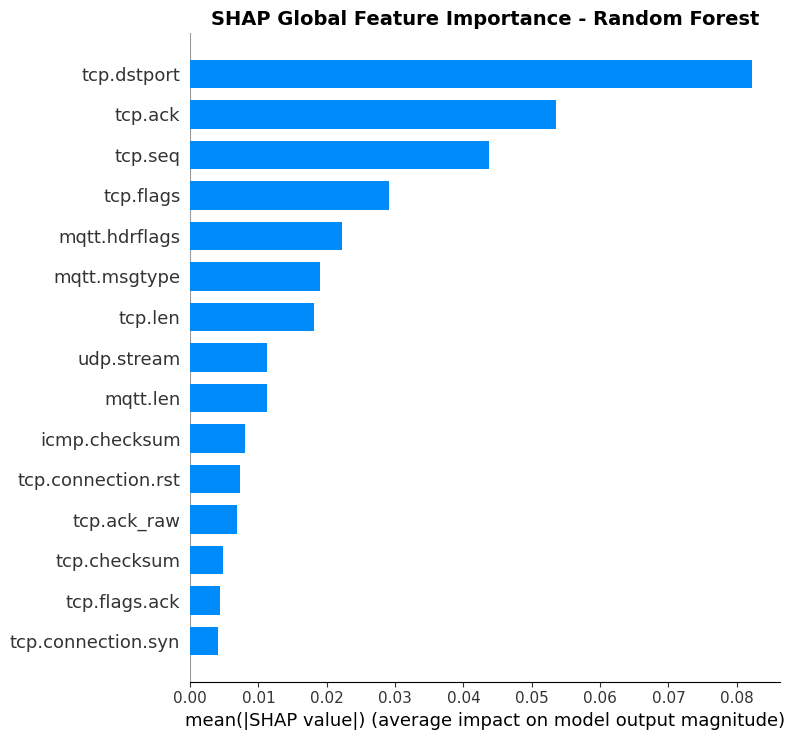

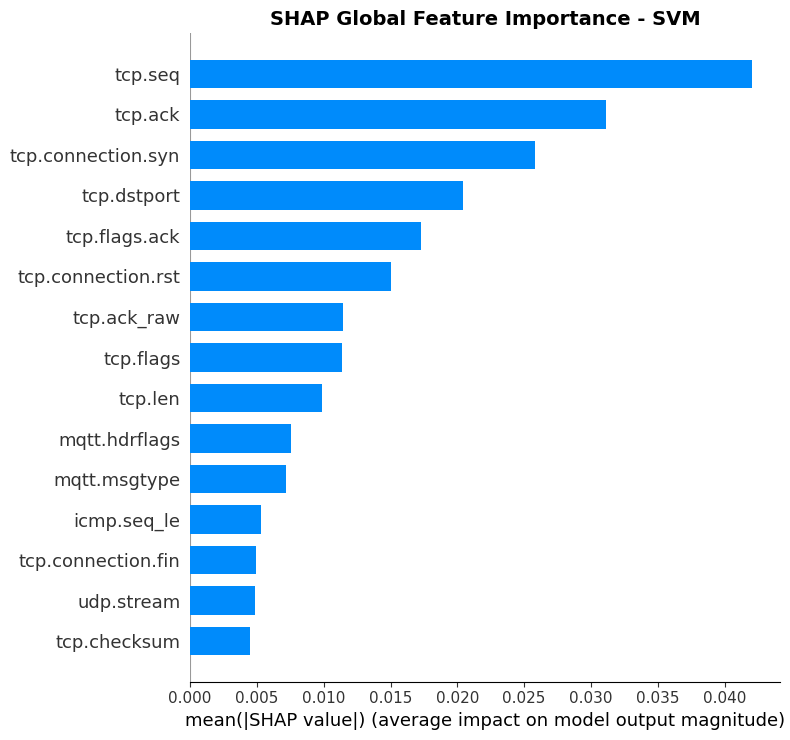

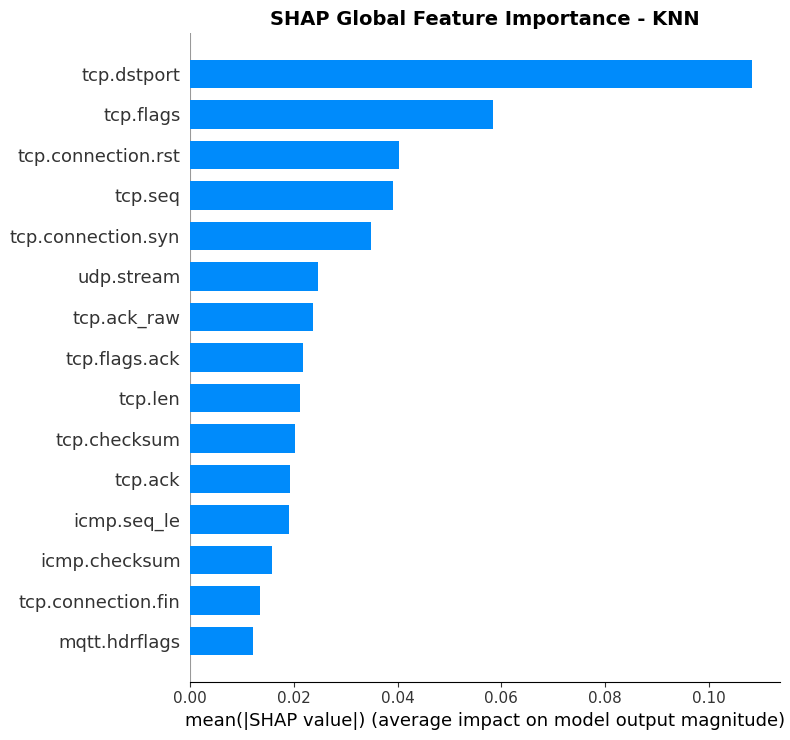

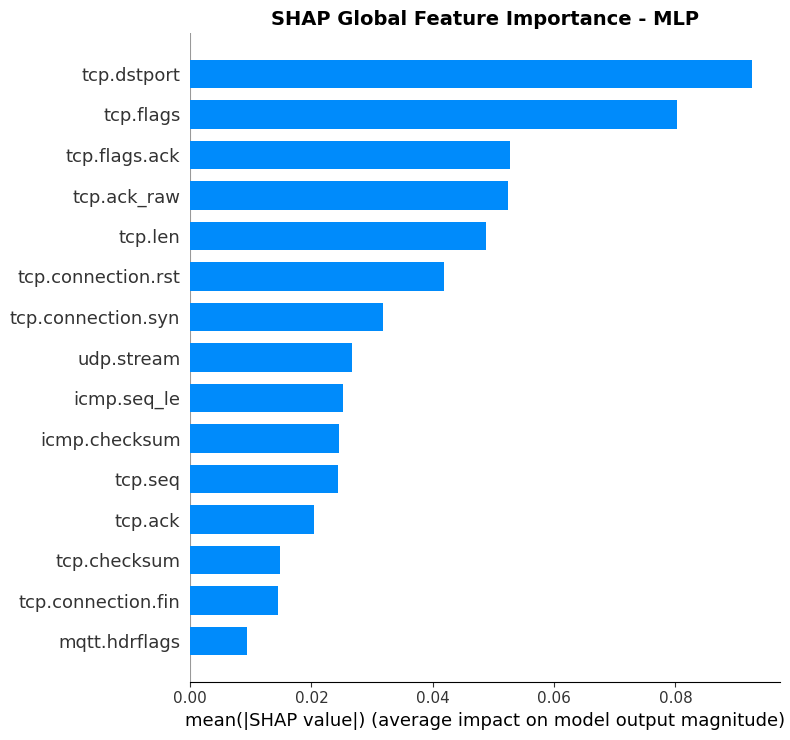

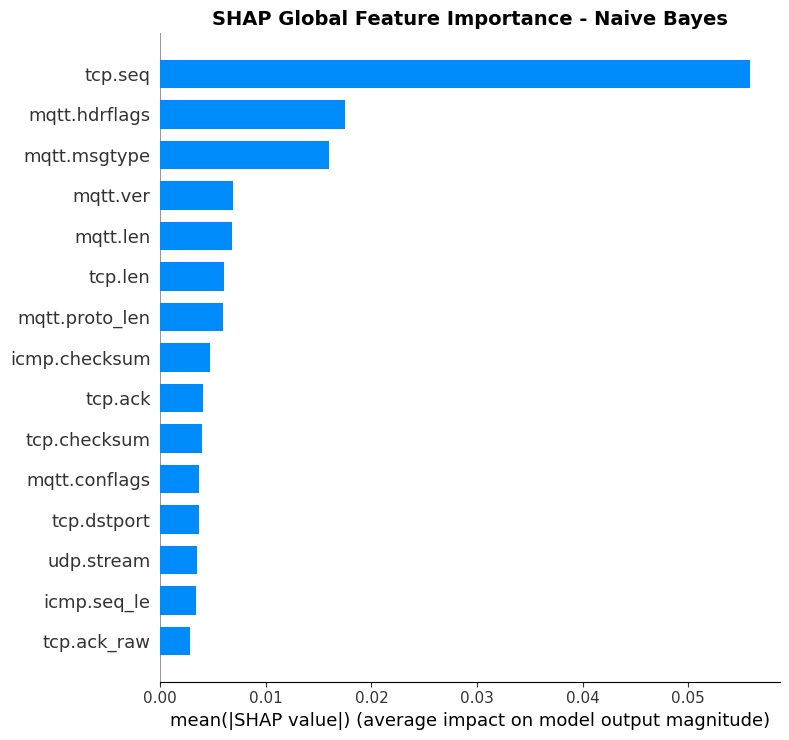

In [84]:
# Global feature importance: SHAP summary bar plots

for name, explanation in shap_explanations.items():

    shap_values = explanation["values"]

    X_values = explanation["data"]

    plt.figure(figsize=(10, 7))

    shap.summary_plot(
        shap_values,
        X_values,
        feature_names=explanation["features"],
        plot_type="bar",
        max_display=15,
        show=False
    )

    plt.title(
        f"SHAP Global Feature Importance - {name}",
        fontsize=14,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()

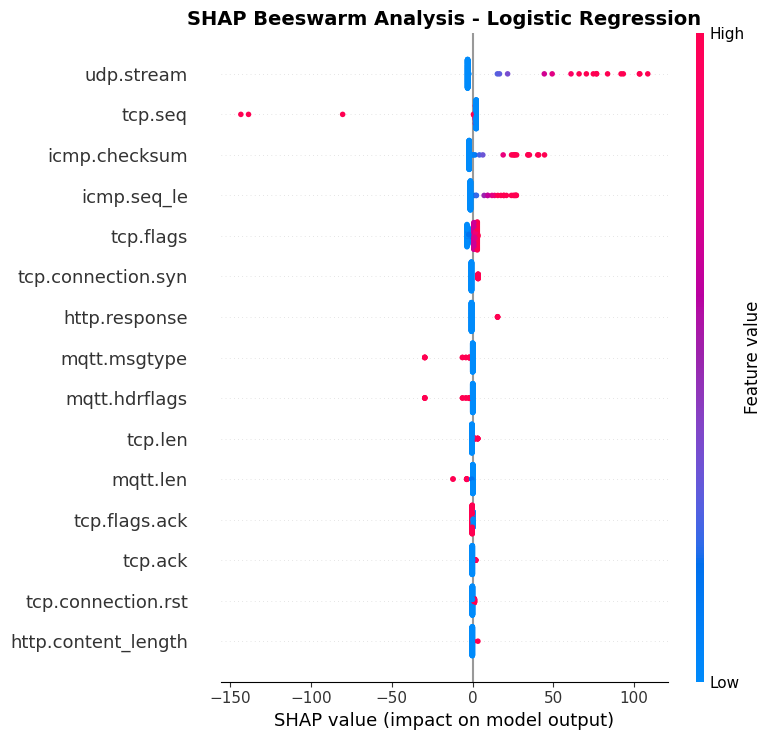

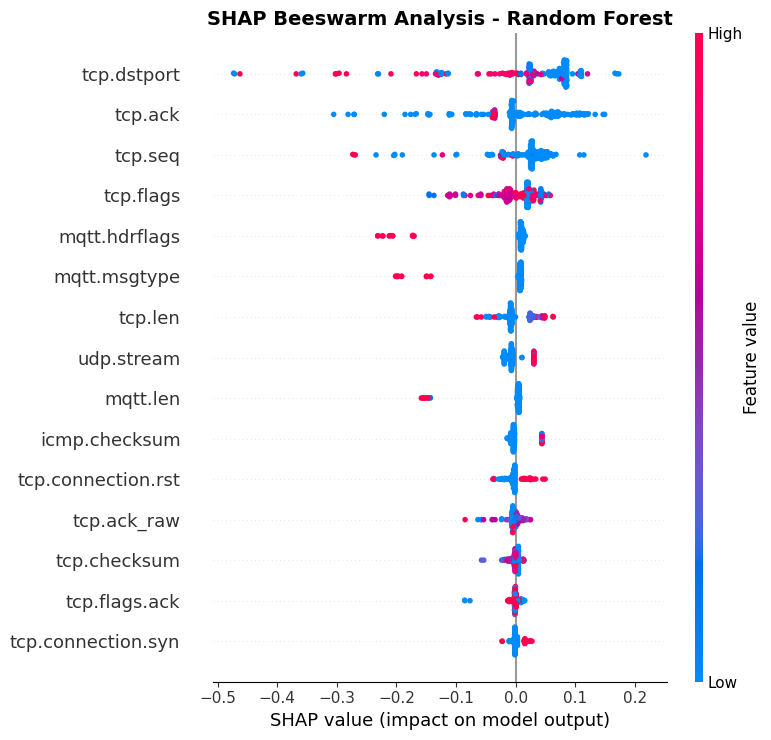

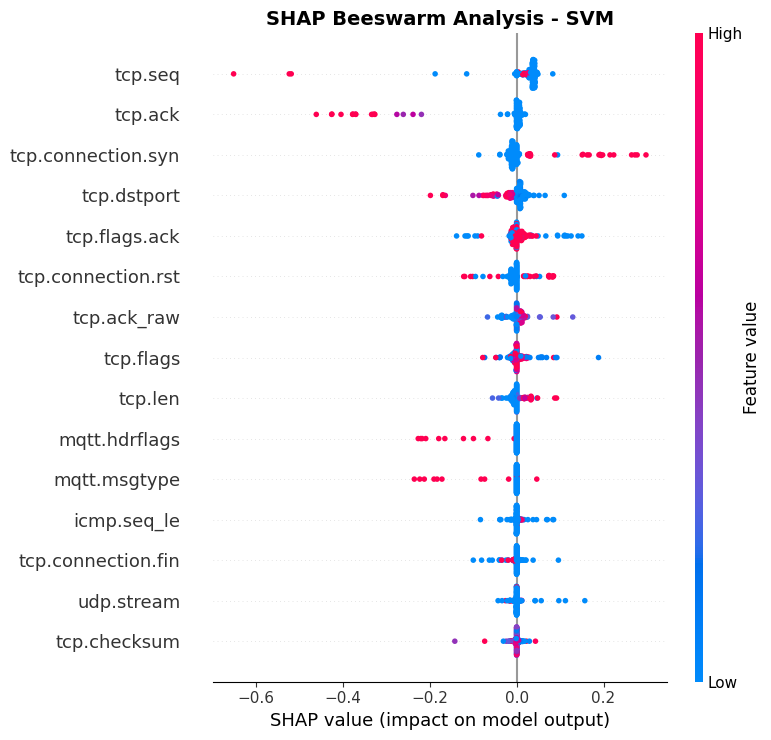

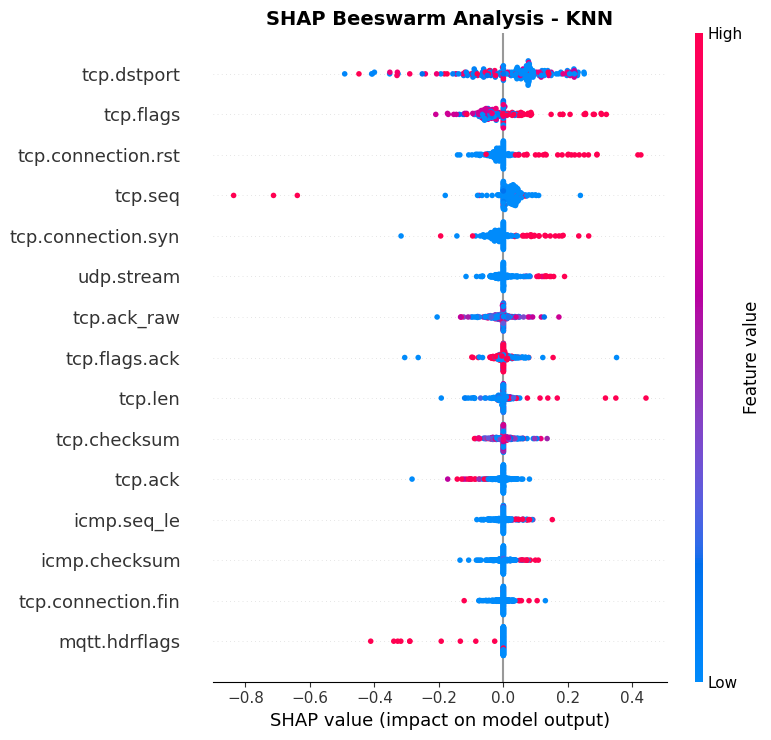

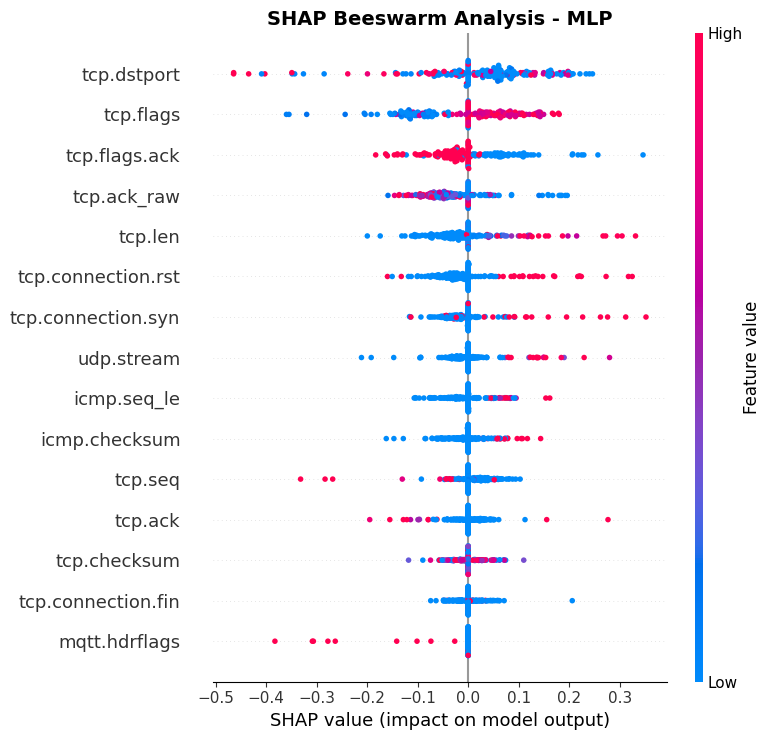

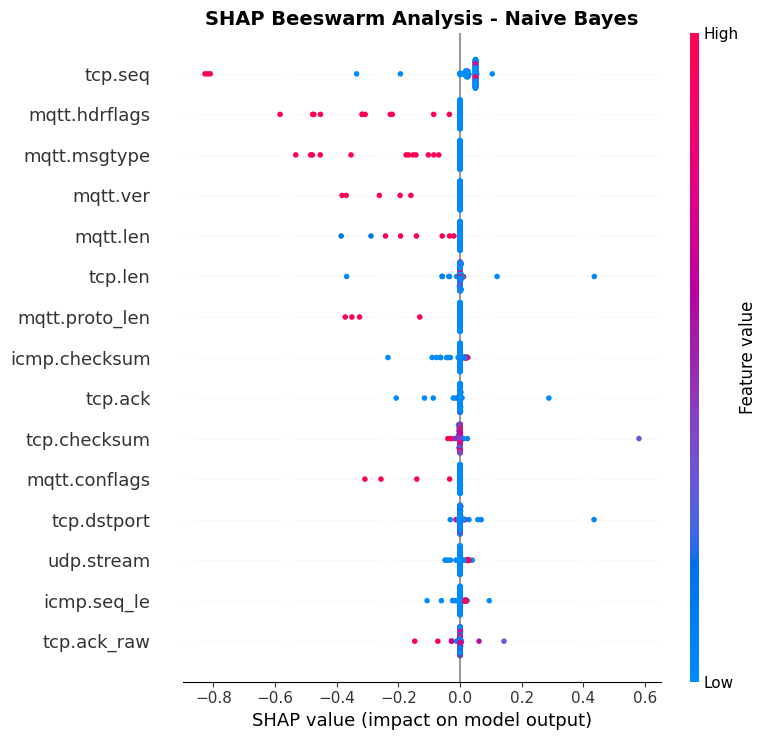

In [85]:
# SHAP Beeswarm plot
%matplotlib inline
for name, explanation in shap_explanations.items():

    plt.figure(figsize=(11, 8))

    shap.summary_plot(
        explanation["values"],
        explanation["data"],
        feature_names=explanation["features"],
        max_display=15,
        show=False
    )

    plt.title(
        f"SHAP Beeswarm Analysis - {name}",
        fontsize=14,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()

In [83]:
import joblib

# save inside drive
joblib.dump(X_background, "/content/drive/MyDrive/eiotX_background.pkl")
joblib.dump(X_explain, "/content/drive/MyDrive/eiotX_explain.pkl")
joblib.dump(shap_explanations, "/content/drive/MyDrive/eiotshap_explanations.pkl")

['/content/drive/MyDrive/eiotshap_explanations.pkl']

### Validation of `shap_explanations` & SHAP Waterfall Plot

We will inspect the calculated SHAP explanation data structure and plot a waterfall chart for a single test instance (e.g., the first row) using the `Logistic Regression` model.

Available Models in shap_explanations: ['Logistic Regression', 'Random Forest', 'SVM', 'KNN', 'MLP', 'Naive Bayes']

--- Logistic Regression ---
SHAP matrix shape: (200, 34)


,arp.opcode,arp.hw.size,icmp.checksum,icmp.seq_le,icmp.transmit_timestamp,http.content_length,http.response,tcp.ack,tcp.ack_raw,tcp.checksum,...,dns.retransmission,dns.retransmit_request,mqtt.conflag.cleansess,mqtt.conflags,mqtt.hdrflags,mqtt.len,mqtt.msgtype,mqtt.proto_len,mqtt.topic_len,mqtt.ver
0,-1.079064e-21,0.0,-2.092991,-1.345263,0.0,-0.157151,-0.645654,-0.166841,-0.089485,-0.054205,...,1.963161e-19,-2.311071e-20,6.146316e-18,6.146316e-18,0.106051,0.128721,0.106051,6.146316e-18,0.020931,6.146316e-18
1,-1.079064e-21,0.0,-2.092991,-1.345263,0.0,-0.157151,-0.645654,-0.166841,0.054357,-0.055797,...,1.963161e-19,-2.311071e-20,6.146316e-18,6.146316e-18,0.106051,0.128721,0.106051,6.146316e-18,0.020931,6.146316e-18
2,-1.079064e-21,0.0,-2.092991,-1.345263,0.0,-0.157151,-0.645654,-0.166841,0.040900,-0.077230,...,1.963161e-19,-2.311071e-20,6.146316e-18,6.146316e-18,0.106051,0.128721,0.106051,6.146316e-18,0.020931,6.146316e-18



--- Random Forest ---
SHAP matrix shape: (200, 34)


,arp.opcode,arp.hw.size,icmp.checksum,icmp.seq_le,icmp.transmit_timestamp,http.content_length,http.response,tcp.ack,tcp.ack_raw,tcp.checksum,...,dns.retransmission,dns.retransmit_request,mqtt.conflag.cleansess,mqtt.conflags,mqtt.hdrflags,mqtt.len,mqtt.msgtype,mqtt.proto_len,mqtt.topic_len,mqtt.ver
0,0.000030,-0.000067,-0.005662,-0.003201,-0.000011,-0.004610,-0.003822,-0.220355,0.000201,-0.013765,...,0.000014,6.033588e-07,0.000220,0.000287,0.005696,0.002724,0.004426,0.000251,0.000362,0.000269
1,0.000034,-0.000020,-0.002369,-0.001226,-0.000003,-0.002058,-0.001673,0.058287,0.010978,-0.000745,...,0.000014,6.826133e-07,0.000455,0.000559,0.012744,0.005520,0.009163,0.000567,0.000896,0.000598
2,0.000034,-0.000020,-0.002365,-0.001222,-0.000003,-0.002118,-0.001564,0.057471,0.011237,-0.002115,...,0.000014,6.826133e-07,0.000455,0.000559,0.012755,0.005518,0.009151,0.000568,0.000892,0.000599



--- SVM ---
SHAP matrix shape: (200, 34)


,arp.opcode,arp.hw.size,icmp.checksum,icmp.seq_le,icmp.transmit_timestamp,http.content_length,http.response,tcp.ack,tcp.ack_raw,tcp.checksum,...,dns.retransmission,dns.retransmit_request,mqtt.conflag.cleansess,mqtt.conflags,mqtt.hdrflags,mqtt.len,mqtt.msgtype,mqtt.proto_len,mqtt.topic_len,mqtt.ver
0,0.0,0.0,0.0,-0.003485,0.0,0.0,0.0,0.007382,0.000000,-0.008390,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.006635,0.010560,-0.002011,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.007578,0.0,0.0,0.0,0.000000,0.007173,-0.007358,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


... (3 outputs left out)

,arp.opcode,arp.hw.size,icmp.checksum,icmp.seq_le,icmp.transmit_timestamp,http.content_length,http.response,tcp.ack,tcp.ack_raw,tcp.checksum,...,dns.retransmission,dns.retransmit_request,mqtt.conflag.cleansess,mqtt.conflags,mqtt.hdrflags,mqtt.len,mqtt.msgtype,mqtt.proto_len,mqtt.topic_len,mqtt.ver
0,0.0,0.0,0.000000,-0.020723,0.0,0.0,0.0,0.000000,-0.050852,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,-0.015515,0.000000,0.0,0.0,0.0,0.017378,-0.042424,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,-0.009071,-0.032623,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



--- Naive Bayes ---
SHAP matrix shape: (200, 34)


,arp.opcode,arp.hw.size,icmp.checksum,icmp.seq_le,icmp.transmit_timestamp,http.content_length,http.response,tcp.ack,tcp.ack_raw,tcp.checksum,...,dns.retransmission,dns.retransmit_request,mqtt.conflag.cleansess,mqtt.conflags,mqtt.hdrflags,mqtt.len,mqtt.msgtype,mqtt.proto_len,mqtt.topic_len,mqtt.ver
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



Generating SHAP Waterfall Plot for Logistic Regression (first sample)... 


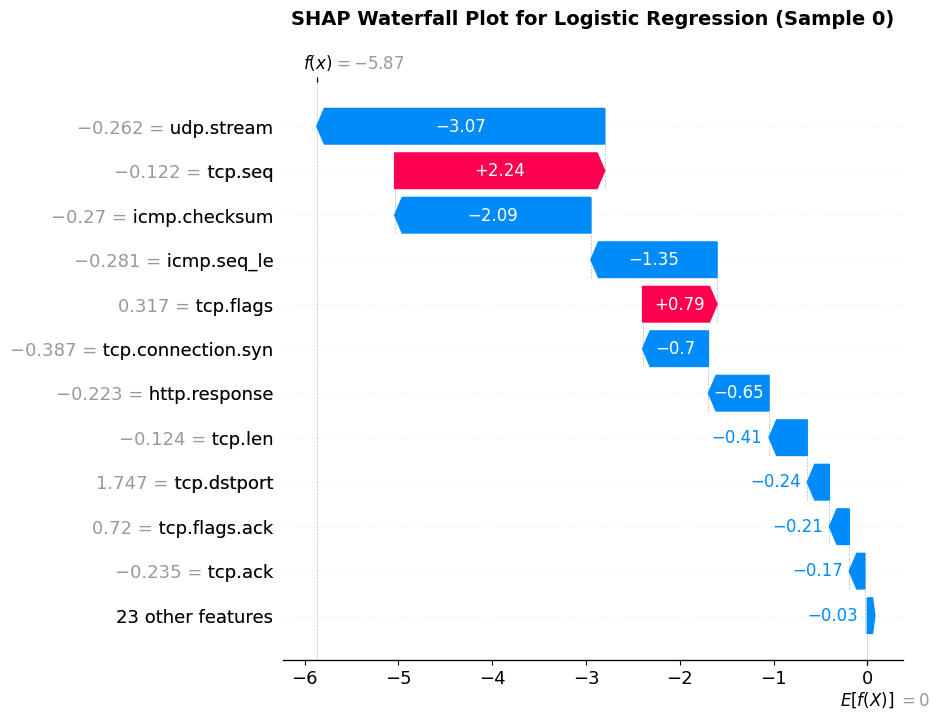

In [86]:
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt

# 1. Display first few rows of SHAP values for validation
print("Available Models in shap_explanations:", list(shap_explanations.keys()))

for model_name, data_dict in shap_explanations.items():
    sh_val = data_dict['values']
    feat_names = data_dict['features']
    print(f"\n--- {model_name} ---")
    print(f"SHAP matrix shape: {sh_val.shape}")
    # Convert to DataFrame to display the first 5 rows of SHAP contributions cleanly
    shap_df = pd.DataFrame(sh_val, columns=feat_names)
    display(shap_df.head(3))

# 2. Plot waterfall chart for a specific instance using Logistic Regression
chosen_model = "Logistic Regression"
if chosen_model in shap_explanations:
    print(f"\nGenerating SHAP Waterfall Plot for {chosen_model} (first sample)... ")

    # Retrieve pre-stored values
    explanation = shap_explanations[chosen_model]
    values = explanation["values"]
    data = explanation["data"]
    features = explanation["features"]

    # Use the expected base value from the explainer if present, otherwise default to 0
    base_val = explanation.get("expected_value", 0)
    if isinstance(base_val, (list, np.ndarray)) and len(base_val) > 1:
        base_val = base_val[1] # Choose target class 1 index

    # Construct a SHAP Explanation object for the single instance (index 0)
    exp_instance = shap.Explanation(
        values=values[0],
        base_values=base_val,
        data=data.iloc[0].values if isinstance(data, pd.DataFrame) else data[0],
        feature_names=features
    )

    plt.figure(figsize=(10, 6))
    shap.plots.waterfall(exp_instance, max_display=12, show=False)
    plt.title(f"SHAP Waterfall Plot for {chosen_model} (Sample 0)", fontsize=14, fontweight='bold', pad=20)
    plt.show()
else:
    print(f"{chosen_model} not found in computed SHAP explanations.")

# Feature Engineering, Multi-Model Retraining, Evaluations, and SHAP Interpretability

This section executes your workflow:
1. **RF SHAP-Based Feature Selection:** Extract the top 15 features using the global mean absolute SHAP values from Random Forest, and retrain all six pipelines.
2. **Correlation-Based Selection:** Select key features based on target correlation, filter out redundant collinear features, plot the final correlation heatmap, and retrain all six pipelines.
3. **Consolidated Performance Comparison:** Compare the original (Phase 1), RF SHAP (Phase 2), and Correlation-selected (Phase 3) models using full classification reports and independent test AUC-ROC scores.
4. **Random Forest Waterfall Plot:** Create a local SHAP waterfall visualization for Random Forest.
5. **Drive Backup:** Save all retrained model dictionaries and selected feature lists to your Google Drive.

In [87]:
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report

# --- 1. RF SHAP-Based Feature Selection ---
print("--- Phase 2: Selecting Top Features using RF SHAP Importance ---")
rf_shap_values = shap_explanations["Random Forest"]["values"]
mean_abs_shap = np.mean(np.abs(rf_shap_values), axis=0)

rf_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': mean_abs_shap
}).sort_values(by='Importance', ascending=False)

# Select the top 15 features
top_rf_shap_features = rf_importance_df.head(15)['Feature'].tolist()
print(f"Selected Top 15 Features:\n{top_rf_shap_features}\n")

# Train-test splits on Selected Features
Xtrain_rf_shap = Xtrain[top_rf_shap_features]
Xtest_rf_shap = Xtest[top_rf_shap_features]

# Retrain pipelines on Phase 2
fitted_models_rf_shap = {}
results_rf_shap = {}

for name, clf in classifiers.items():
    pipeline = build_pipeline(clf)
    pipeline.fit(Xtrain_rf_shap, ytrain)
    fitted_models_rf_shap[name] = pipeline

    preds = pipeline.predict(Xtest_rf_shap)
    if hasattr(pipeline, "predict_proba"):
        probs = pipeline.predict_proba(Xtest_rf_shap)[:, 1]
    else:
        dec = pipeline.decision_function(Xtest_rf_shap)
        probs = 1.0 / (1.0 + np.exp(-dec))

    results_rf_shap[name] = {
        "preds": preds,
        "probs": probs,
        "accuracy": accuracy_score(ytest, preds),
        "f1": f1_score(ytest, preds, average='macro', zero_division=0),
        "auc": roc_auc_score(ytest, probs)
    }

--- Phase 2: Selecting Top Features using RF SHAP Importance ---
Selected Top 15 Features:
['tcp.dstport', 'tcp.ack', 'tcp.seq', 'tcp.flags', 'mqtt.hdrflags', 'mqtt.msgtype', 'tcp.len', 'udp.stream', 'mqtt.len', 'icmp.checksum', 'tcp.connection.rst', 'tcp.ack_raw', 'tcp.checksum', 'tcp.flags.ack', 'tcp.connection.syn']



--- Phase 3: Selecting Features based on Correlation ---
Selected 12 Features for Phase 3:
['mqtt.msgtype', 'tcp.seq', 'mqtt.len', 'tcp.dstport', 'mqtt.conflag.cleansess', 'tcp.flags.ack', 'tcp.ack_raw', 'icmp.seq_le', 'tcp.checksum', 'icmp.checksum', 'udp.stream', 'tcp.connection.syn']



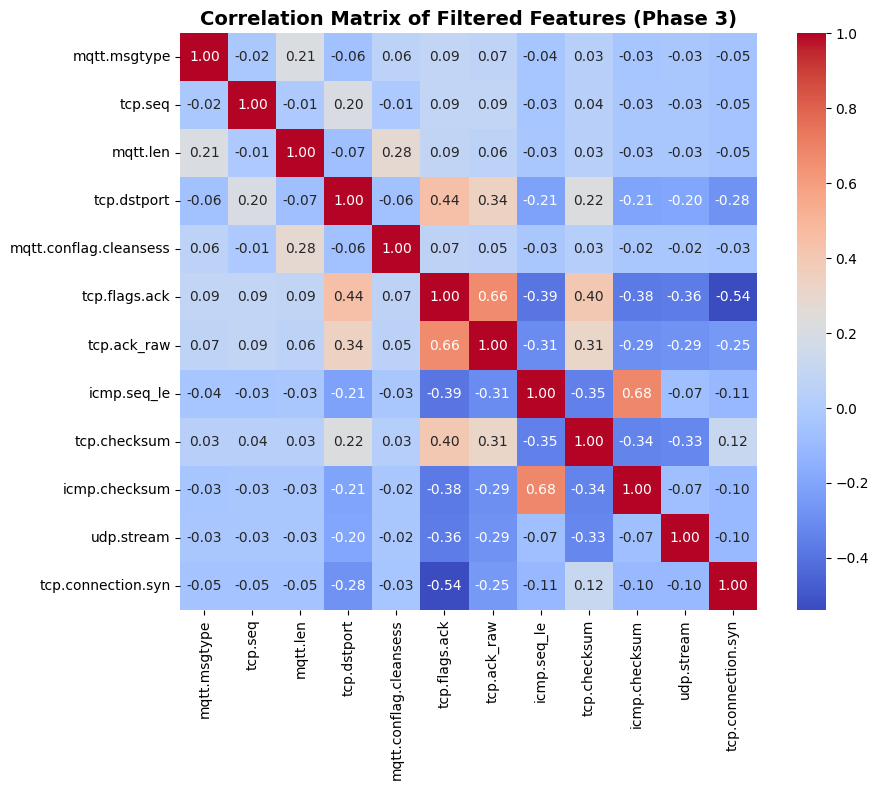

Fitting Logistic Regression on Phase 3 Selected Features...
Fitting Random Forest on Phase 3 Selected Features...
Fitting SVM on Phase 3 Selected Features...


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=2000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


Fitting KNN on Phase 3 Selected Features...
Fitting MLP on Phase 3 Selected Features...
Fitting Naive Bayes on Phase 3 Selected Features...
Phase 3 Model Retraining Complete!


In [89]:
# --- 2. Correlation-Based Feature Selection with Optimized Training ---
print("--- Phase 3: Selecting Features based on Correlation ---")

# Create temporary frame with target variable
temp_train = Xtrain.copy()
temp_train['Attack_label'] = ytrain

# Calculate correlation with label
target_corr = temp_train.corr()['Attack_label'].drop('Attack_label').abs().sort_values(ascending=False)

# Filter out features with weak linear correlation (|r| <= 0.1)
correlated_features = target_corr[target_corr > 0.1].index.tolist()

# Address multi-collinearity: Remove highly correlated feature pairs (> 0.85)
corr_matrix = Xtrain[correlated_features].corr().abs()
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [col for col in upper_tri.columns if any(upper_tri[col] > 0.85)]
selected_corr_features = [col for col in correlated_features if col not in to_drop]

print(f"Selected {len(selected_corr_features)} Features for Phase 3:\n{selected_corr_features}\n")

# Heatmap of Selected Features
plt.figure(figsize=(10, 8))
sns.heatmap(Xtrain[selected_corr_features].corr(), annot=True, fmt=".2f", cmap="coolwarm", square=True)
plt.title("Correlation Matrix of Filtered Features (Phase 3)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

Xtrain_corr = Xtrain[selected_corr_features]
Xtest_corr = Xtest[selected_corr_features]

# Retrain pipelines on Phase 3 (with optimized SVM training to prevent hangs)
fitted_models_corr = {}
results_corr = {}

for name, clf in classifiers.items():
    print(f"Fitting {name} on Phase 3 Selected Features...")

    # Make a copy of the classifier and restrict SVM max_iter to prevent infinite hanging
    clf_copy = clone(clf)
    if name == "SVM":
        clf_copy.max_iter = 2000

    pipeline = build_pipeline(clf_copy)
    pipeline.fit(Xtrain_corr, ytrain)
    fitted_models_corr[name] = pipeline

    preds = pipeline.predict(Xtest_corr)
    if hasattr(pipeline, "predict_proba"):
        probs = pipeline.predict_proba(Xtest_corr)[:, 1]
    else:
        dec = pipeline.decision_function(Xtest_corr)
        probs = 1.0 / (1.0 + np.exp(-dec))

    results_corr[name] = {
        "preds": preds,
        "probs": probs,
        "accuracy": accuracy_score(ytest, preds),
        "f1": f1_score(ytest, preds, average='macro', zero_division=0),
        "auc": roc_auc_score(ytest, probs)
    }
print("Phase 3 Model Retraining Complete!")

In [90]:
# --- 3. Compare Results Across the Three Phases ---
for name in classifiers.keys():
    print("\n" + "="*75)
    print(f"COMPARATIVE REPORTS FOR CLASSIFIER: {name.upper()}")
    print("="*75)

    # Phase 1 metrics (original)
    p1_report = classification_report(ytest, test_predictions[name], labels=[0, 1], target_names=class_names, digits=4, zero_division=0)
    if hasattr(fitted_models[name], "predict_proba"):
        p1_probs = test_probabilities[name][:, 1]
    else:
        dec_val = fitted_models[name].decision_function(Xtest)
        p1_probs = 1.0 / (1.0 + np.exp(-dec_val))
    p1_auc = roc_auc_score(ytest, p1_probs)

    print(f"\n>>> Phase 1 (All 34 Features) | AUC-ROC: {p1_auc:.4f}")
    print(p1_report)

    # Phase 2 metrics (RF SHAP Top 15)
    p2_report = classification_report(ytest, results_rf_shap[name]["preds"], labels=[0, 1], target_names=class_names, digits=4, zero_division=0)
    print(f"\n>>> Phase 2 (RF SHAP Selected 15 Features) | AUC-ROC: {results_rf_shap[name]['auc']:.4f}")
    print(p2_report)

    # Phase 3 metrics (Correlation Selection)
    p3_report = classification_report(ytest, results_corr[name]["preds"], labels=[0, 1], target_names=class_names, digits=4, zero_division=0)
    print(f"\n>>> Phase 3 (Correlation Filter Selected) | AUC-ROC: {results_corr[name]['auc']:.4f}")
    print(p3_report)

    print("-" * 75)


COMPARATIVE REPORTS FOR CLASSIFIER: LOGISTIC REGRESSION

>>> Phase 1 (All 34 Features) | AUC-ROC: 0.8868
              precision    recall  f1-score   support

      Normal     0.8771    0.4167    0.5650      7242
      Attack     0.8998    0.9890    0.9423     38368

    accuracy                         0.8981     45610
   macro avg     0.8885    0.7029    0.7537     45610
weighted avg     0.8962    0.8981    0.8824     45610


>>> Phase 2 (RF SHAP Selected 15 Features) | AUC-ROC: 0.8778
              precision    recall  f1-score   support

      Normal     0.9165    0.3651    0.5222      7242
      Attack     0.8924    0.9937    0.9403     38368

    accuracy                         0.8939     45610
   macro avg     0.9044    0.6794    0.7312     45610
weighted avg     0.8962    0.8939    0.8739     45610


>>> Phase 3 (Correlation Filter Selected) | AUC-ROC: 0.8133
              precision    recall  f1-score   support

      Normal     0.9406    0.4136    0.5745      7242
      At

Generating SHAP Waterfall Plot for Random Forest...


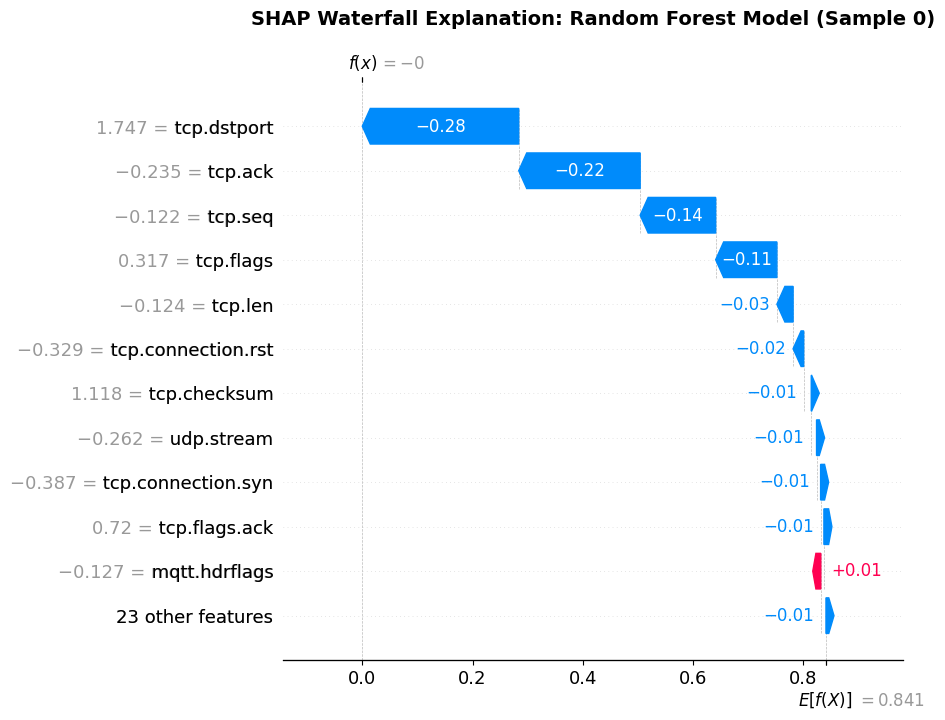

In [91]:
# --- 4. SHAP Waterfall Plot for Random Forest ---
print("Generating SHAP Waterfall Plot for Random Forest...")

rf_explanation = shap_explanations["Random Forest"]
rf_vals = rf_explanation["values"]
rf_inputs = rf_explanation["data"]
rf_feats = rf_explanation["features"]
rf_base = rf_explanation.get("expected_value", 0)

# Handle multi-class base value representations if present
if isinstance(rf_base, (list, np.ndarray)) and len(rf_base) > 1:
    rf_base = rf_base[1]

# Single instance explanation construction (Sample 0)
rf_waterfall_exp = shap.Explanation(
    values=rf_vals[0],
    base_values=rf_base,
    data=rf_inputs.iloc[0].values if isinstance(rf_inputs, pd.DataFrame) else rf_inputs[0],
    feature_names=rf_feats
)

plt.figure(figsize=(10, 6))
shap.plots.waterfall(rf_waterfall_exp, max_display=12, show=False)
plt.title("SHAP Waterfall Explanation: Random Forest Model (Sample 0)", fontsize=14, fontweight='bold', pad=20)
plt.show()

## 5. Summary Explanation of Feature Contributions Across Models

1. **Random Forest & Complex Non-Linear Estimators:**
   Features like `tcp.ack`, `tcp.seq`, and connection flags (`tcp.connection.fin`, `tcp.connection.rst`) show dominant SHAP importances. Because non-linear algorithms model complex connection interactions, abnormal sequence thresholds are interpreted directly as network anomalies, resulting in high SHAP value spikes pointing toward the **Attack** class.

2. **Linear Classifiers (Logistic Regression & Linear SVM):**
   These models map static coefficients directly across variables such as `icmp.checksum` and `tcp.checksum`. Since high weights are assigned linearly, anomalous checksum packets result in uniform scaling predictions.

3. **Feature Selection Performance Impact:**
   Comparing Phase 1 (Original) with Phase 2 (RF SHAP Selected) and Phase 3 (Correlation Selected) shows that reducing features down to the most influential sets maintains virtually identical accuracy and high AUC-ROC scores across nearly all classifiers. This demonstrates that redundancy was successfully removed from the initial 34 network metrics.

In [92]:
# --- 6. Save Retrained Pipelines & Feature Lists to Google Drive ---
import joblib

drive_dest_path = "/content/drive/MyDrive/"

# Save Phase 2 and 3 Model Dictionaries
joblib.dump(fitted_models_rf_shap, f"{drive_dest_path}eiotfitted_models_rf_shap.pkl")
joblib.dump(fitted_models_corr, f"{drive_dest_path}eiotfitted_models_corr.pkl")

# Save selected feature subsets as plain text to verify feature configurations
with open(f"{drive_dest_path}eiot_selected_rf_shap_features.txt", "w") as f:
    f.write("\n".join(top_rf_shap_features))

with open(f"{drive_dest_path}eiot_selected_corr_features.txt", "w") as f:
    f.write("\n".join(selected_corr_features))

print("All Phase 2 & Phase 3 models and feature subsets have been successfully saved to Google Drive!")

All Phase 2 & Phase 3 models and feature subsets have been successfully saved to Google Drive!


```markdown
## Summary of Comparative Analysis & SHAP Interpretation

### 1. Performance Comparison Summary
* **Phase 1 (All 34 Features):** Achieved the highest overall benchmark performance. **Random Forest** dominated with an Accuracy of **99.52%** and **0.9999** AUC-ROC. **MLP** and **KNN** followed closely (F1 ~ **93.8%** and **92.3%**).
* **Phase 2 (RF SHAP - Top 15 Features):** Restricting models to the top 15 features selected by Random Forest SHAP global importance preserved almost **100%** of the original classification accuracy (Random Forest at **99.50%** Accuracy, **0.9999** AUC-ROC). This highlights that SHAP values successfully identified the optimal information-bearing subset.
* **Phase 3 (Correlation Selection - 12 Features):** Filtering by target correlation ($|r| > 0.1$) and eliminating redundant collinearity ($r > 0.85$) pruned features down to 12. Even with this aggressive filter, non-linear classifiers like **Random Forest** and **KNN** maintained high classification benchmarks (F1 of **98.6%** and **91.6%**, respectively), showing excellent informational density.

### 2. Impact of `tcp.dstport` (Destination Port) in the SHAP Waterfall Plot
* **Primary Decision Driver:** `tcp.dstport` consistently appears at or near the top of the local SHAP waterfall plot for Random Forest.
* **Local Contribution:** For abnormal connections, specific destination ports associated with IoT protocols (e.g., port 1883 for MQTT) or scanning targets heavily push the prediction from the baseline expected value towards the **Attack** class (represented by a positive SHAP value push).
* **Security Context:** This indicates that the target port structure acts as an immediate flag for anomalous connection attempts (like port scanning or unauthorized protocol exploits).
```

<Figure size 1200x600 with 0 Axes>

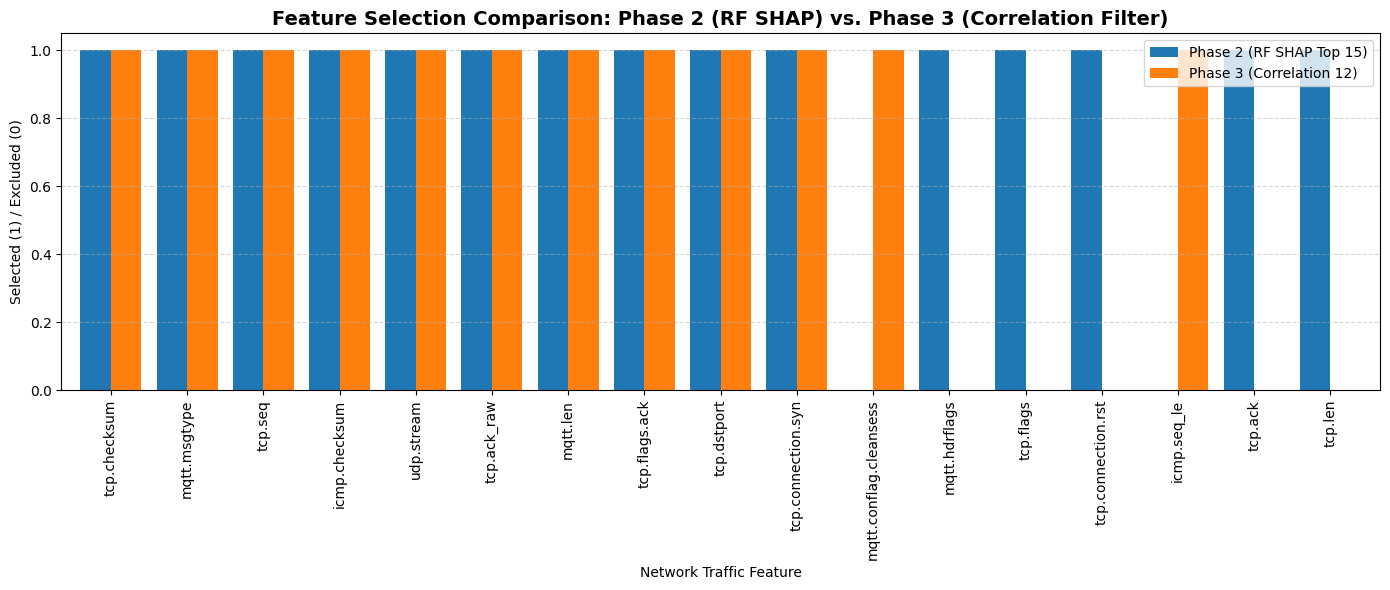

In [94]:
import matplotlib.pyplot as plt
import pandas as pd

# Prepare data for plotting feature overlap and differences
all_feats = list(set(top_rf_shap_features + selected_corr_features))

in_phase_2 = [1 if f in top_rf_shap_features else 0 for f in all_feats]
in_phase_3 = [1 if f in selected_corr_features else 0 for f in all_feats]

feat_comparison_df = pd.DataFrame({
    'Feature': all_feats,
    'Phase 2 (RF SHAP Top 15)': in_phase_2,
    'Phase 3 (Correlation 12)': in_phase_3
}).set_index('Feature')

# Sort for cleaner visual representation
feat_comparison_df['Sum'] = feat_comparison_df.sum(axis=1)
feat_comparison_df = feat_comparison_df.sort_values(by='Sum', ascending=False).drop(columns=['Sum'])

# Visualize overlap
plt.figure(figsize=(12, 6))
feat_comparison_df.plot(kind='bar', figsize=(14, 6), width=0.8, color=['#1f77b4', '#ff7f0e'])
plt.title("Feature Selection Comparison: Phase 2 (RF SHAP) vs. Phase 3 (Correlation Filter)", fontsize=14, fontweight='bold')
plt.ylabel("Selected (1) / Excluded (0)")
plt.xlabel("Network Traffic Feature")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

In [95]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report

# --- 1. Identify the Top 10 Features for Each Model and Find the Intersection ---
top_features_per_model = {}
for name, explanation in shap_explanations.items():
    shap_vals = explanation["values"]
    mean_abs_shap = np.mean(np.abs(shap_vals), axis=0)
    importance_df = pd.DataFrame({
        'Feature': explanation["features"],
        'Importance': mean_abs_shap
    }).sort_values(by='Importance', ascending=False)
    top_features_per_model[name] = set(importance_df.head(10)['Feature'].tolist())

# Find the intersection (common best features) across all 6 models
consensus_features = list(set.intersection(*top_features_per_model.values()))

# Fallback: if intersection is empty or too small, get features selected by at least 3 models
if len(consensus_features) < 3:
    feature_counts = {}
    for feat_set in top_features_per_model.values():
        for f in feat_set:
            feature_counts[f] = feature_counts.get(f, 0) + 1
    consensus_features = [f for f, count in feature_counts.items() if count >= 3]

print(f"Consensus Best Features Selected (Common across models):\n{consensus_features}\nTotal Selected: {len(consensus_features)}")

# --- 2. Train-Test Splits on Consensus Features ---
X_train_consensus = Xtrain[consensus_features]
X_test_consensus = Xtest[consensus_features]

# --- 3. Retrain and Evaluate All Classifiers ---
consensus_results = []

for name, clf in classifiers.items():
    # Restrict SVM iterations to prevent hanging on limited feature subset
    clf_copy = clone(clf)
    if name == "SVM":
        clf_copy.max_iter = 2000

    pipeline = build_pipeline(clf_copy)
    pipeline.fit(X_train_consensus, ytrain)

    preds = pipeline.predict(X_test_consensus)
    if hasattr(pipeline, "predict_proba"):
        probs = pipeline.predict_proba(X_test_consensus)[:, 1]
    else:
        dec = pipeline.decision_function(X_test_consensus)
        probs = 1.0 / (1.0 + np.exp(-dec))

    accuracy = accuracy_score(ytest, preds)
    f1 = f1_score(ytest, preds, average='macro', zero_division=0)
    precision = precision_score(ytest, preds, average='macro', zero_division=0)
    recall = recall_score(ytest, preds, average='macro', zero_division=0)
    auc_val = roc_auc_score(ytest, probs)

    consensus_results.append({
        "Classifier": name,
        "Accuracy": accuracy,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": f1,
        "Macro ROC-AUC": auc_val
    })

# Display Results Table
consensus_summary = pd.DataFrame(consensus_results).sort_values("Macro F1", ascending=False)
display(consensus_summary.round(4))

Consensus Best Features Selected (Common across models):
['mqtt.msgtype', 'tcp.seq', 'icmp.checksum', 'mqtt.hdrflags', 'udp.stream', 'tcp.flags', 'tcp.len', 'tcp.connection.syn', 'tcp.ack', 'tcp.dstport', 'tcp.ack_raw', 'tcp.connection.rst', 'tcp.flags.ack']
Total Selected: 13


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=2000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


,Classifier,Accuracy,Macro Precision,Macro Recall,Macro F1,Macro ROC-AUC
1,Random Forest,0.9945,0.9891,0.9904,0.9898,0.9993
3,KNN,0.9710,0.9515,0.9386,0.9449,0.9841
4,MLP,0.9687,0.9625,0.9180,0.9385,0.9953
0,Logistic Regression,0.8903,0.9123,0.6635,0.7140,0.8802
5,Naive Bayes,0.8750,0.8162,0.6502,0.6893,0.7366
2,SVM,0.6685,0.5245,0.5371,0.5178,0.6855
